Project: C:\Users\haru4\研究\研究コード\LSM
Python: c:\Users\haru4\AppData\Local\Python\pythoncore-3.14-64\python.exe
Input: C:\Users\haru4\研究\研究コード\LSM\g_tactile_results\calibration\all_materials


,Material,Trials,Training / split,Test / split
0,aluminum_board,324,226,98
1,outer_pigskin,324,226,98
2,back_pigskin,324,226,98
3,cork,324,226,98
4,denim,324,226,98
5,rubber_board,324,226,98
6,Japanese_paper,324,226,98
7,wood_board,324,226,98


States: (2592, 80, 20) | Original features: 1600
[Full features] split 1/10: 98.98%
[Full features] split 2/10: 98.98%
[Full features] split 3/10: 97.58%
[Full features] split 4/10: 99.74%
[Full features] split 5/10: 99.87%
[Full features] split 6/10: 99.87%
[Full features] split 7/10: 99.74%
[Full features] split 8/10: 97.83%
[Full features] split 9/10: 99.62%
[Full features] split 10/10: 99.23%


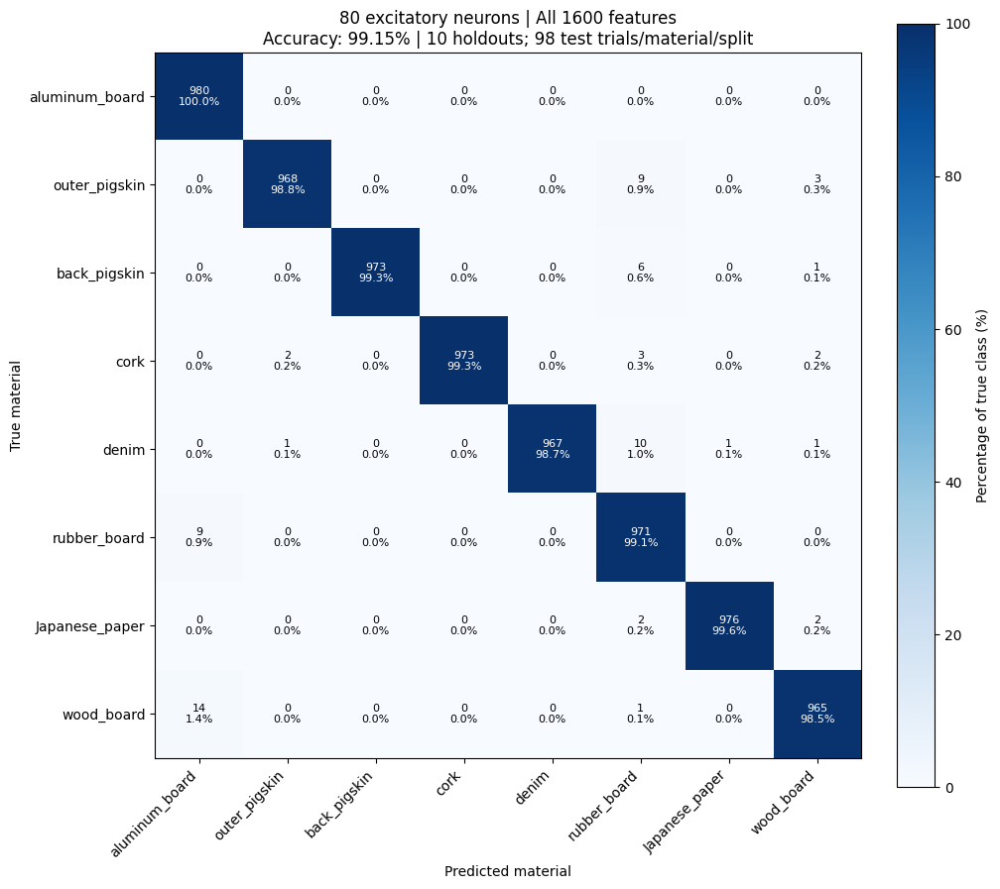

Full-feature accuracy: 99.1454%


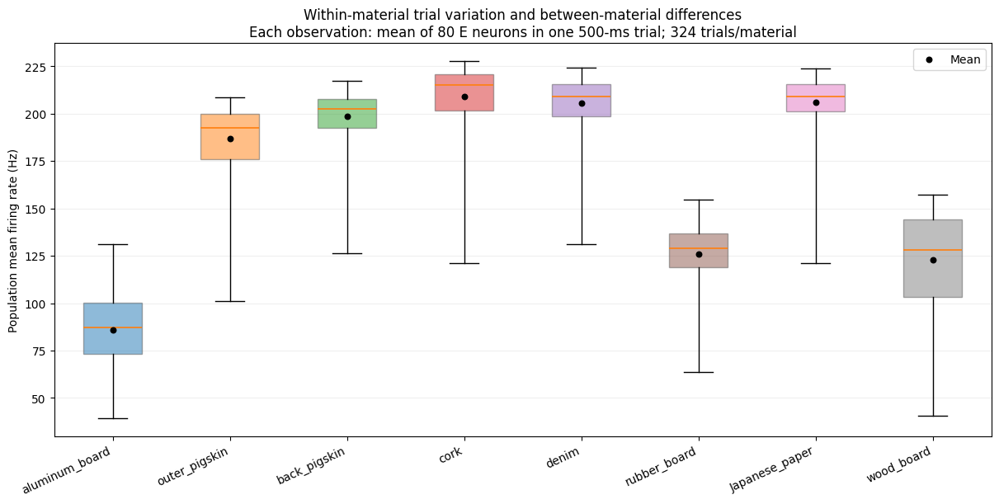

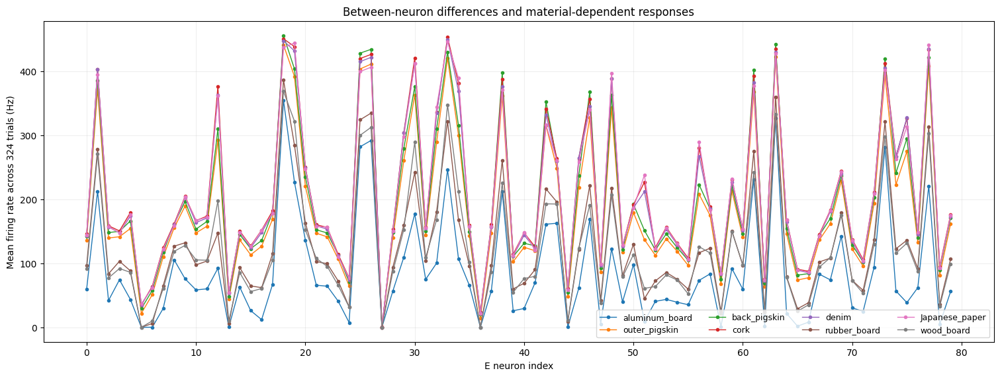

In [1]:
# 最初にこのセルを実行：状態読み込み → 全次元の分類 → 混同行列
from pathlib import Path
import sys
import os
import json
import hashlib
import time

# h_analysis内から開いても、プロジェクト直下から開いても動くようにする。
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / 'd_tools' / 'pca.py').is_file()
             and (p / 'c_configs' / 'FIXED' / 'calibration_reference.npz').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('LSM内を作業フォルダとして実行してください。')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if 'get_ipython' in globals() and get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
print('Project:', ROOT)
print('Python:', sys.executable)

SOURCE_DIR = ROOT / 'g_tactile_results' / 'calibration' / 'all_materials'
REFERENCE_FILE = ROOT / 'c_configs' / 'FIXED' / 'calibration_reference.npz'
FEATURE_KEY = 'counts_25ms'
NEURON_IDS = np.arange(80)  # E0〜E79。抑制性は含めない。
BIN_MS = 25.0
MAX_PCS = 40
REGULARIZATION = 1e-6
THREADS = 4

MATERIALS = json.loads(REFERENCE_FILE.with_suffix('.json').read_text(encoding='utf-8'))['materials']
print('Input:', SOURCE_DIR)

reference_metadata = json.loads(REFERENCE_FILE.with_suffix('.json').read_text(encoding='utf-8'))
assert hashlib.sha256(REFERENCE_FILE.read_bytes()).hexdigest() == reference_metadata['sha256']
with np.load(REFERENCE_FILE) as data:
    trial_order = data['trial_order'].copy()
    train_indices = data['train_indices'].copy()
    test_indices = data['test_indices'].copy()

state_parts, feature_files = [], []
for material_index, material in enumerate(MATERIALS):
    path = SOURCE_DIR / material / 'features.npz'
    with np.load(path) as data:
        counts = data[FEATURE_KEY]
        ids = data['trial_ids']
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f'{material}: 試行IDが重複しています。')
    by_id = {int(sid): i for i, sid in enumerate(ids)}
    positions = [by_id[int(sid)] for sid in trial_order[material_index]]
    state_parts.append(counts[positions][:, NEURON_IDS, :] / (BIN_MS / 1000.0))
    feature_files.append(path)

n_classes = len(MATERIALS)
n_trials_per_material = len(trial_order[0])
states = np.concatenate(state_parts, axis=0)
labels = np.repeat(np.arange(n_classes), n_trials_per_material)
splits = [(np.concatenate([m*n_trials_per_material+tr for m in range(n_classes)]),
           np.concatenate([m*n_trials_per_material+te for m in range(n_classes)]))
          for tr, te in zip(train_indices, test_indices)]
n_splits = len(splits)
n_train_each, n_test_each = train_indices.shape[1], test_indices.shape[1]
n_features = int(np.prod(states.shape[1:]))
assert states.shape == (2592, 80, 20)
assert (n_splits, n_train_each, n_test_each) == (10, 226, 98)
display(pd.DataFrame({'Material': MATERIALS,
    'Trials': n_trials_per_material, 'Training / split': n_train_each,
    'Test / split': n_test_each}))
print('States:', states.shape, '| Original features:', n_features)


# 全1600次元の分類（PCA・標準化なし）。10分割の評価結果を加算する。
from threadpoolctl import threadpool_limits
from d_tools.classification import classify
from d_tools.evaluation import evaluate_classification, confusion_percentages

full_feature_matrix = states.reshape(len(states), -1)
full_confusion_counts = np.zeros((n_classes, n_classes), dtype=np.int64)
full_confusion_folds = []
full_confusion_predictions = []
with threadpool_limits(limits=THREADS):
    for fold, (training_ids, evaluation_ids) in enumerate(splits, 1):
        train_x = full_feature_matrix[training_ids]
        # 過去の解析と同じく、学習側で一度も活動しない特徴だけを除く。
        active = np.any(train_x != 0, axis=0)
        predicted = classify(train_x[:, active], labels[training_ids],
                             full_feature_matrix[evaluation_ids][:, active],
                             regularization=REGULARIZATION)
        metrics = evaluate_classification(labels[evaluation_ids], predicted,
                                          labels=np.arange(n_classes))
        full_confusion_counts += metrics['confusion_matrix']
        full_confusion_folds.append({'fold': fold, 'accuracy': metrics['accuracy']})
        full_confusion_predictions.append(pd.DataFrame({
            'fold': fold, 'ordered_trial_index': evaluation_ids,
            'true_material': np.asarray(MATERIALS)[labels[evaluation_ids]],
            'predicted_material': np.asarray(MATERIALS)[predicted],
        }))
        print(f'[Full features] split {fold}/{n_splits}: {metrics["accuracy"]:.2%}')

assert np.all(full_confusion_counts.sum(axis=1) == n_splits*n_test_each)
full_confusion_accuracy = float(np.trace(full_confusion_counts)/full_confusion_counts.sum())
full_confusion_percent = confusion_percentages(full_confusion_counts)
confusion_title = (
    f'{len(NEURON_IDS)} excitatory neurons | All {n_features} features\n'
    f'Accuracy: {full_confusion_accuracy:.2%} | {n_splits} holdouts; '
    f'{n_test_each} test trials/material/split'
)
# ファイルには保存せず、ノートブック内に表示する。
fig, ax = plt.subplots(figsize=(10, 9), layout='constrained')
im = ax.imshow(full_confusion_percent, cmap='Blues', vmin=0, vmax=100)
for row in range(n_classes):
    for col in range(n_classes):
        value = full_confusion_percent[row, col]
        ax.text(col, row, f'{full_confusion_counts[row, col]}\n{value:.1f}%',
                ha='center', va='center', fontsize=8,
                color='white' if value > 50 else 'black')
ax.set_xticks(range(n_classes), MATERIALS, rotation=45, ha='right')
ax.set_yticks(range(n_classes), MATERIALS)
ax.set(xlabel='Predicted material', ylabel='True material', title=confusion_title)
fig.colorbar(im, ax=ax, label='Percentage of true class (%)')
plt.show()
print(f'Full-feature accuracy: {full_confusion_accuracy:.4%}')


# --- Firing-rate variation across trials, materials, and neurons ---
# statesの単位はHz、形は（素材別に並んだ試行、Eニューロン、25 ms時間ビン）。
# 1点の試行平均：80ニューロンと500 ms全体を平均する。
material_trial_states = states.reshape(
    n_classes, n_trials_per_material, len(NEURON_IDS), states.shape[-1])
trial_population_rates_hz = material_trial_states.mean(axis=(2, 3))  # 素材×324試行
neuron_material_rates_hz = material_trial_states.mean(axis=(1, 3))  # 素材×80ニューロン
material_rate_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red',
                        'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray']

# 箱：25〜75パーセンタイル、横線：中央値、ひげ：全試行の最小〜最大、黒丸：平均。
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
boxes = ax.boxplot([rates for rates in trial_population_rates_hz],
                   patch_artist=True, whis=(0, 100), showmeans=False,
                   medianprops={'color': 'tab:orange', 'linewidth': 1.2})
for box, color in zip(boxes['boxes'], material_rate_colors):
    box.set(facecolor=color, edgecolor='0.35', alpha=0.5)
ax.scatter(np.arange(1, n_classes+1), trial_population_rates_hz.mean(axis=1),
           color='black', s=22, zorder=3, label='Mean')
ax.set_xticks(np.arange(1, n_classes+1), MATERIALS, rotation=25, ha='right')
ax.set(ylabel='Population mean firing rate (Hz)',
       title=('Within-material trial variation and between-material differences\n'
              f'Each observation: mean of {len(NEURON_IDS)} E neurons in one '
              f'{states.shape[-1]*BIN_MS:g}-ms trial; {n_trials_per_material} trials/material'))
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.2)
ax.legend(loc='upper right')
plt.show()

# 各素材で324試行と時間を平均し、ニューロンごとの応答を比較する。
fig, ax = plt.subplots(figsize=(15, 5.6), layout='constrained')
for material, rates, color in zip(MATERIALS, neuron_material_rates_hz, material_rate_colors):
    ax.plot(NEURON_IDS, rates, 'o-', color=color, markersize=3, linewidth=1,
            label=material)
ax.set(xlabel='E neuron index',
       ylabel=f'Mean firing rate across {n_trials_per_material} trials (Hz)',
       title='Between-neuron differences and material-dependent responses')
ax.set_axisbelow(True)
ax.grid(alpha=0.2)
ax.legend(loc='lower right', ncol=4, fontsize=9)
plt.show()


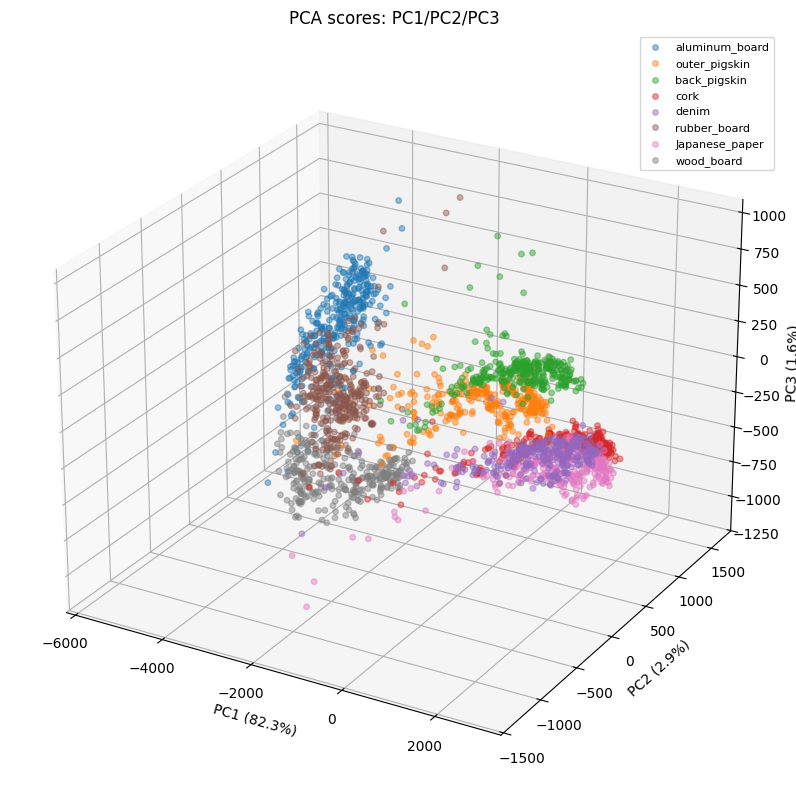

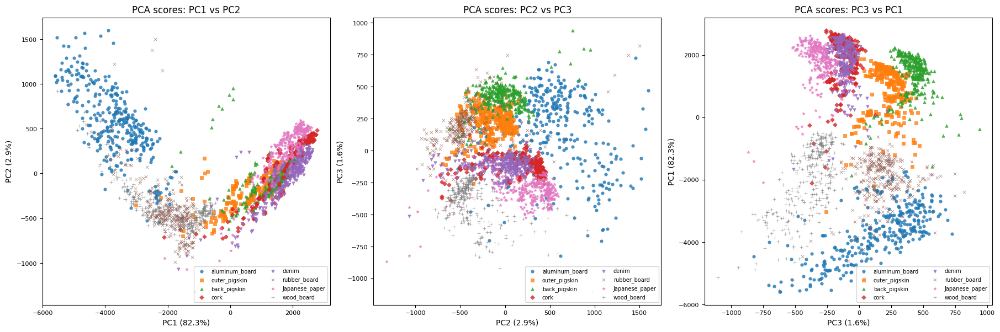

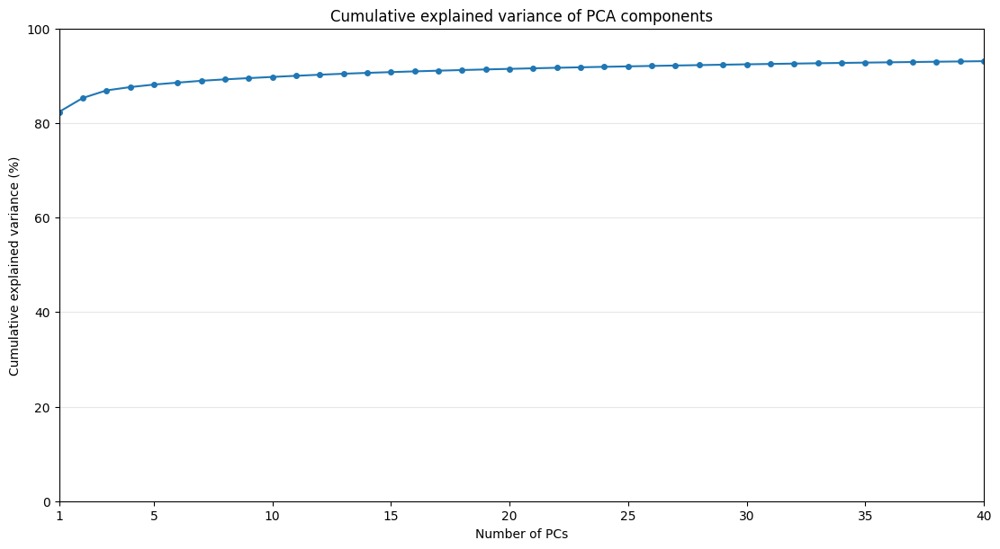

All-trial visualization PCA | 2592 trials | no standardization
Cumulative explained variance through PC40: 93.08%


In [2]:
# PCAの可視化：3D散布図、3通りの2D散布図、PC1〜PC40の累積寄与率。
# この可視化だけは全2592試行でPCAを計算する。分類評価の学習側PCAとは別。
# 平均中心化のみで、標準化は行わない。画像・数値はファイルへ保存しない。
from d_tools.pca import fit_pca, transform_pca
from threadpoolctl import threadpool_limits

if 'states' not in globals() or 'labels' not in globals():
    raise RuntimeError('先頭のセルで状態を読み込んでから実行してください。')
with threadpool_limits(limits=THREADS):
    visualization_pca = fit_pca(states, n_components=MAX_PCS)
    visualization_scores = transform_pca(states, visualization_pca)
# PCA軸の符号は任意。最大絶対係数が正になる向きで散布図を統一する。
axis_peaks = np.argmax(np.abs(visualization_pca.axes), axis=0)
visualization_signs = np.sign(visualization_pca.axes[axis_peaks, np.arange(MAX_PCS)])
visualization_signs[visualization_signs == 0] = 1
visualization_scores *= visualization_signs
visualization_variance_percent = (
    visualization_pca.explained_variance / visualization_pca.total_variance * 100)
visualization_cumulative_percent = np.cumsum(visualization_variance_percent)
visualization_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red',
                        'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray']
visualization_markers = ['o', 's', '^', 'D', 'v', 'x', '*', '+']

def visualization_pc_label(index):
    return f'PC{index+1} ({visualization_variance_percent[index]:.1f}%)'

# 1．PC1・PC2・PC3の3D散布図。
fig = plt.figure(figsize=(8, 8), layout='constrained')
ax3d = fig.add_subplot(111, projection='3d')
for class_id, (material, color) in enumerate(zip(MATERIALS, visualization_colors)):
    points = visualization_scores[labels == class_id]
    ax3d.scatter(points[:, 0], points[:, 1], points[:, 2], s=16,
                 color=color, alpha=0.45, label=material)
ax3d.set(xlabel=visualization_pc_label(0), ylabel=visualization_pc_label(1),
         zlabel=visualization_pc_label(2), title='PCA scores: PC1/PC2/PC3')
ax3d.view_init(elev=25, azim=-60)
ax3d.legend(loc='upper right', fontsize=8)
plt.show()

# 2．3枚の小グラフの大きさ・余白・文字・素材の記号を統一する。格子なし。
fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout='constrained')
for ax, (horizontal, vertical) in zip(axes, [(0, 1), (1, 2), (2, 0)]):
    for class_id, (material, color, marker) in enumerate(
            zip(MATERIALS, visualization_colors, visualization_markers)):
        points = visualization_scores[labels == class_id]
        ax.scatter(points[:, horizontal], points[:, vertical], color=color,
                   marker=marker, s=15, linewidths=0.5, alpha=0.8, label=material)
    ax.set(xlabel=visualization_pc_label(horizontal),
           ylabel=visualization_pc_label(vertical),
           title=f'PCA scores: PC{horizontal+1} vs PC{vertical+1}')
    ax.set_box_aspect(1)
    ax.grid(False)
    ax.tick_params(labelsize=8)
    ax.legend(loc='lower right', ncol=2, fontsize=7)
plt.show()

# 3．全1600次元の総分散を分母にした累積寄与率。表示した40成分内では正規化しない。
fig, ax = plt.subplots(figsize=(11, 6), layout='constrained')
ax.plot(np.arange(1, MAX_PCS+1), visualization_cumulative_percent,
        'o-', color='tab:blue', markersize=4, linewidth=1.5)
ax.set(xlabel='Number of PCs', ylabel='Cumulative explained variance (%)',
       title='Cumulative explained variance of PCA components',
       xlim=(1, MAX_PCS), ylim=(0, 100))
ax.set_xticks([1, *range(5, MAX_PCS+1, 5)])
ax.set_yticks(np.arange(0, 101, 20))
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.3)
plt.show()
print(f'All-trial visualization PCA | {len(states)} trials | no standardization')
print(f'Cumulative explained variance through PC{MAX_PCS}: '
      f'{visualization_cumulative_percent[-1]:.2f}%')


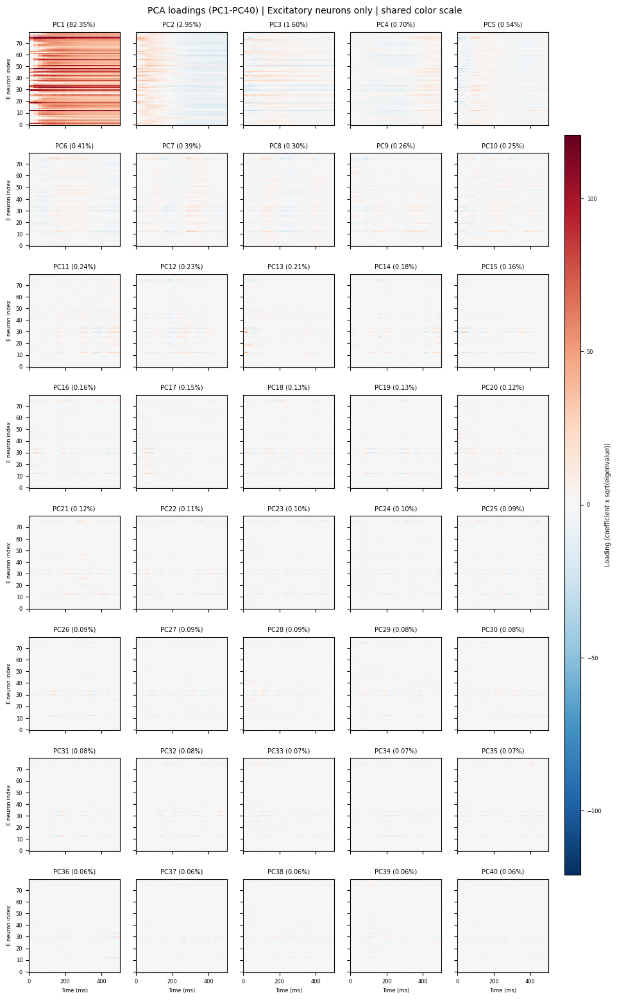

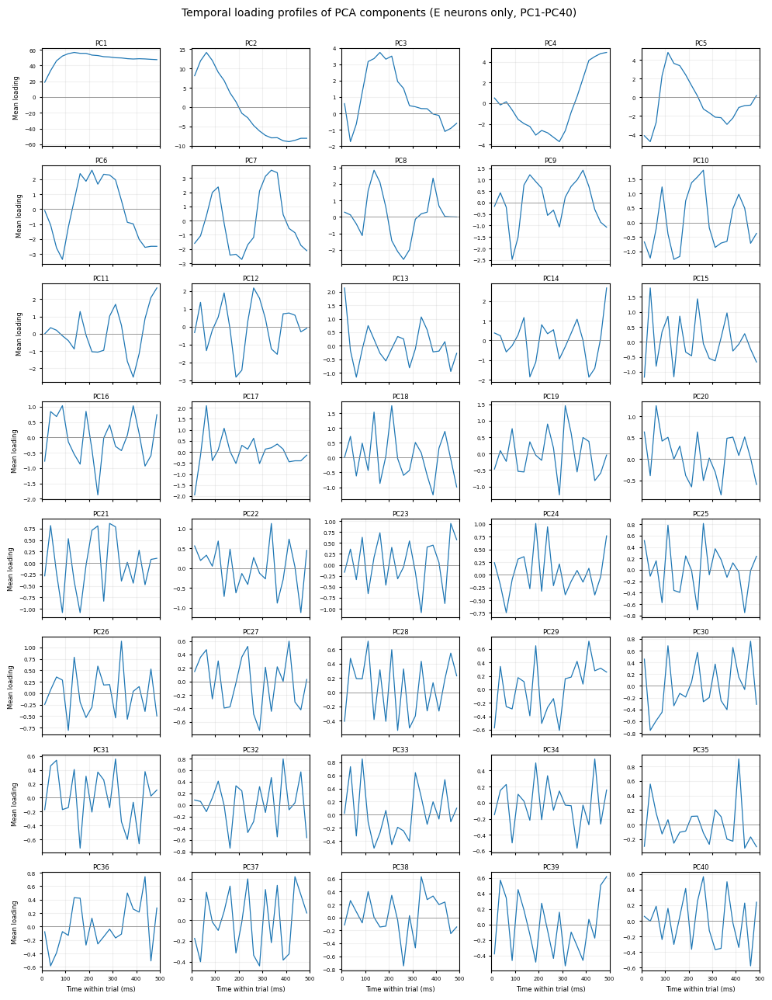

In [3]:
# PC1〜PC40のローディング：ニューロン×時間ヒートマップと時間波形。
from d_tools.pca import loading_maps

if 'visualization_pca' not in globals():
    raise RuntimeError('2つ目のセルでPCAを計算してから実行してください。')
# ローディング = PCA係数 × sqrt(主成分の分散)。散布図と同じ符号へそろえる。
pc_loading_maps = loading_maps(visualization_pca, scaled=True)
pc_loading_maps = pc_loading_maps * visualization_signs[:, None, None]
pc_temporal_loading_profiles = pc_loading_maps.mean(axis=1)  # 80ニューロンの符号付き平均
loading_n_pc, loading_n_neurons, loading_n_bins = pc_loading_maps.shape
loading_n_columns = 5
loading_n_rows = (loading_n_pc + loading_n_columns - 1) // loading_n_columns
loading_duration_ms = loading_n_bins * BIN_MS
loading_time_ms = (np.arange(loading_n_bins) + 0.5) * BIN_MS
loading_color_limit = float(np.max(np.abs(pc_loading_maps))) or 1.0

# 1．全40枚で、ゼロを中心とした同じ色範囲を使う。
heatmap_fig, heatmap_axes = plt.subplots(loading_n_rows, loading_n_columns,
    figsize=(10, 2*loading_n_rows), squeeze=False)
heatmap_fig.subplots_adjust(left=0.07, right=0.88, bottom=0.045, top=0.96,
                            wspace=0.18, hspace=0.30)
for k, ax in enumerate(heatmap_axes.flat):
    if k >= loading_n_pc:
        ax.set_visible(False)
        continue
    loading_image = ax.imshow(pc_loading_maps[k], origin='lower', aspect='auto',
        interpolation='nearest', extent=(0, loading_duration_ms, -0.5, loading_n_neurons-0.5),
        cmap='RdBu_r', vmin=-loading_color_limit, vmax=loading_color_limit)
    ax.set_title(f'PC{k+1} ({visualization_variance_percent[k]:.2f}%)', fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_xticks([0, 200, 400])
    if k % loading_n_columns == 0:
        ax.set_ylabel('E neuron index', fontsize=6)
    else:
        ax.tick_params(labelleft=False)
    if k // loading_n_columns == loading_n_rows-1:
        ax.set_xlabel('Time (ms)', fontsize=6)
    else:
        ax.tick_params(labelbottom=False)
colorbar_ax = heatmap_fig.add_axes([0.905, 0.14, 0.025, 0.72])
colorbar = heatmap_fig.colorbar(loading_image, cax=colorbar_ax)
colorbar.set_label('Loading (coefficient x sqrt(eigenvalue))', fontsize=7)
colorbar.ax.tick_params(labelsize=6)
heatmap_fig.suptitle(f'PCA loadings (PC1-PC{loading_n_pc}) | Excitatory neurons only | shared color scale',
                     fontsize=10, y=0.985)
plt.show()

# 2．各PCを80ニューロンで平均した時間波形。帯は付けない。
# 小グラフの大きさと余白は全パネルで統一し、5列×8行の縦長配置にする。
profile_fig, profile_axes = plt.subplots(loading_n_rows, loading_n_columns,
    figsize=(10, 1.65*loading_n_rows), squeeze=False)
profile_fig.subplots_adjust(left=0.065, right=0.99, bottom=0.045, top=0.945,
                            wspace=0.27, hspace=0.20)
for k, ax in enumerate(profile_axes.flat):
    if k >= loading_n_pc:
        ax.set_visible(False)
        continue
    ax.plot(loading_time_ms, pc_temporal_loading_profiles[k], color='tab:blue', linewidth=0.9)
    ax.axhline(0, color='0.55', linewidth=0.6)
    ax.set_title(f'PC{k+1}', fontsize=6, pad=3)
    ax.set_xlim(0, loading_duration_ms)
    ax.set_xticks(np.arange(0, loading_duration_ms+1, 100))
    if k == 0:
        pc1_limit = float(np.max(np.abs(pc_temporal_loading_profiles[0]))) * 1.1 or 1.0
        ax.set_ylim(-pc1_limit, pc1_limit)
    ax.tick_params(labelsize=5, length=2)
    ax.grid(True, alpha=0.18)
    if k % loading_n_columns == 0:
        ax.set_ylabel('Mean loading', fontsize=6)
    if k // loading_n_columns == loading_n_rows-1:
        ax.set_xlabel('Time within trial (ms)', fontsize=6)
    else:
        ax.tick_params(labelbottom=False)
profile_fig.suptitle(
    f'Temporal loading profiles of PCA components (E neurons only, PC1-PC{loading_n_pc})',
    fontsize=10, y=0.985)
plt.show()


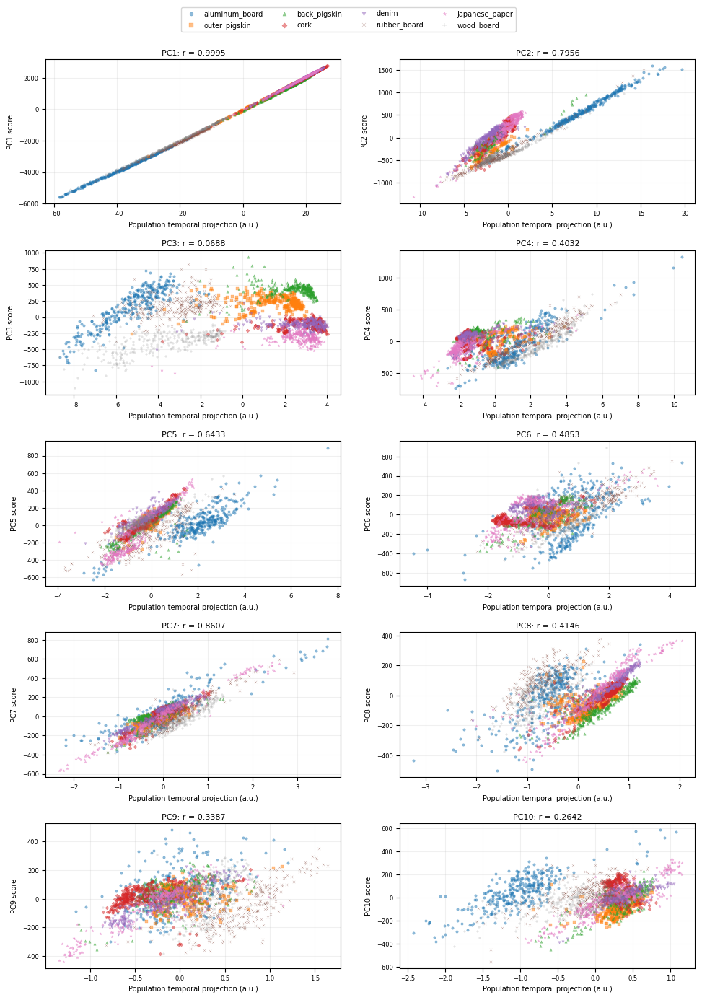

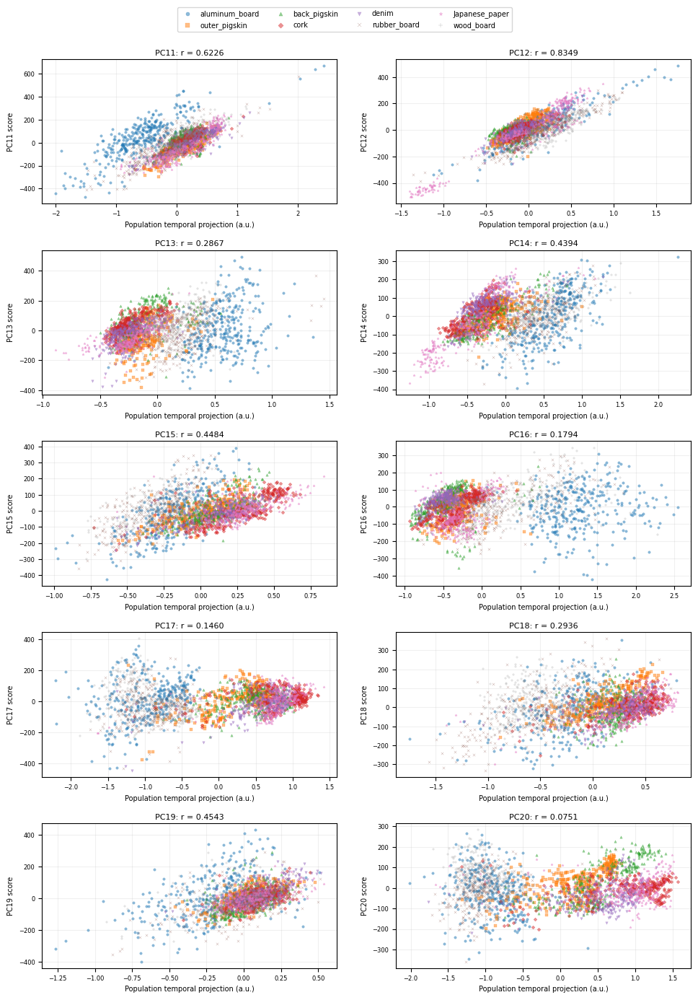

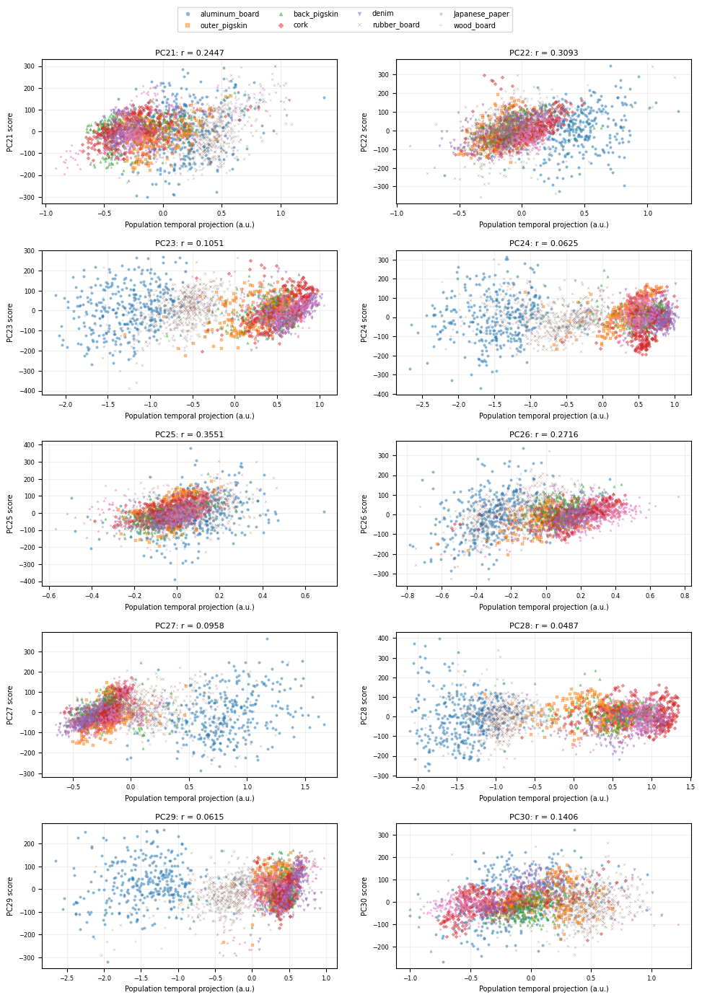

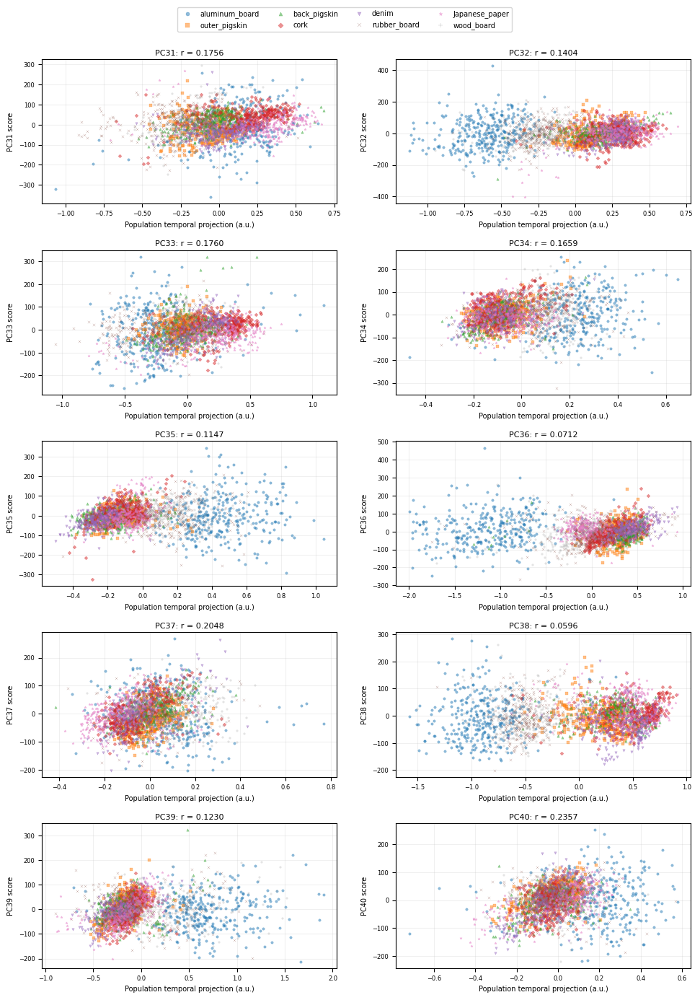

In [4]:
# 集団平均の時間応答とPCスコアの相関（PC1〜PC40）。
# ローディング図の次に実行。結果ファイルは保存しない。
from d_tools.pca import loading_maps

if 'visualization_pca' not in globals():
    raise RuntimeError('2つ目のセルでPCAを計算してから実行してください。')
# PCAスコア用の元の係数を80ニューロンで平均する（固有値の平方根は掛けない）。
population_pc_weights = loading_maps(visualization_pca, scaled=False)
population_pc_weights = population_pc_weights * visualization_signs[:, None, None]
population_temporal_weights = population_pc_weights.mean(axis=1)
# 各ニューロン・時間ビンの全試行平均を引き、ニューロン方向に平均。
# 素材ごとの平均は引かない。
population_centered_states = states - visualization_pca.mean.reshape(states.shape[1:])
population_rate_residuals = population_centered_states.mean(axis=1)
# 横軸 F_i,k = sum_t mean_n(W_k(n,t)) * mean_n(centered r_i(n,t))
population_temporal_projections = population_rate_residuals @ population_temporal_weights.T
population_temporal_correlations = np.full(visualization_scores.shape[1], np.nan)
for k in range(visualization_scores.shape[1]):
    if np.std(population_temporal_projections[:, k]) > 0 and np.std(visualization_scores[:, k]) > 0:
        population_temporal_correlations[k] = np.corrcoef(
            population_temporal_projections[:, k], visualization_scores[:, k])[0, 1]

population_correlation_figures = []
for first_pc in range(0, visualization_scores.shape[1], 10):
    last_pc = min(first_pc+10, visualization_scores.shape[1])
    fig, axes = plt.subplots(5, 2, figsize=(10, 14), squeeze=False)
    fig.subplots_adjust(left=0.08, right=0.98, bottom=0.04, top=0.94,
                        wspace=0.20, hspace=0.32)
    for offset, ax in enumerate(axes.flat):
        k = first_pc + offset
        if k >= last_pc:
            ax.set_visible(False)
            continue
        for class_id, (material, color, marker) in enumerate(
                zip(MATERIALS, visualization_colors, visualization_markers)):
            mask = labels == class_id
            ax.scatter(population_temporal_projections[mask, k], visualization_scores[mask, k],
                       s=6, alpha=0.5, color=color, marker=marker, linewidths=0.3, label=material)
        ax.set_title(f'PC{k+1}: r = {population_temporal_correlations[k]:.4f}', fontsize=8, pad=4)
        ax.set_xlabel('Population temporal projection (a.u.)', fontsize=7)
        ax.set_ylabel(f'PC{k+1} score', fontsize=7)
        ax.tick_params(labelsize=6)
        ax.set_axisbelow(True)
        ax.grid(True, alpha=0.18)
    handles, names = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, names, loc='upper center', ncol=4, fontsize=7,
               bbox_to_anchor=(0.5, 0.995), markerscale=1.5)
    population_correlation_figures.append(fig)
    plt.show()


[Pattern reconstruction] split 1/5
[Pattern reconstruction] split 2/5
[Pattern reconstruction] split 3/5
[Pattern reconstruction] split 4/5
[Pattern reconstruction] split 5/5


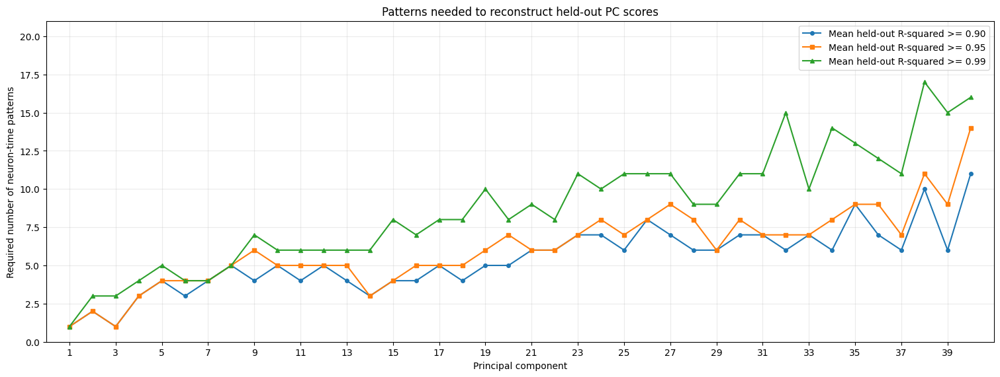

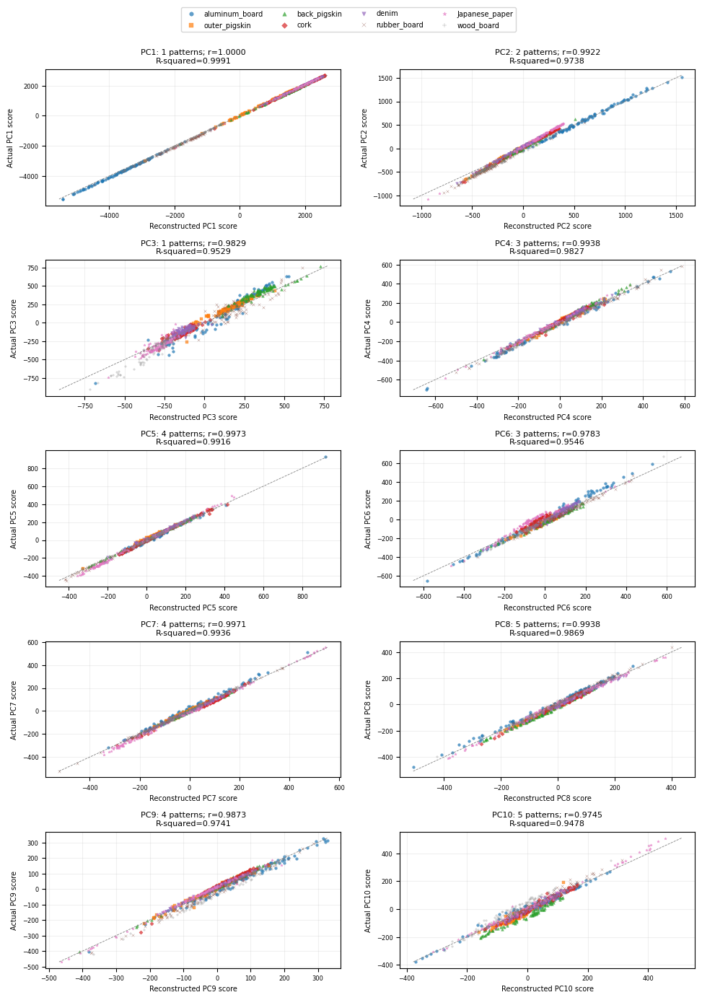

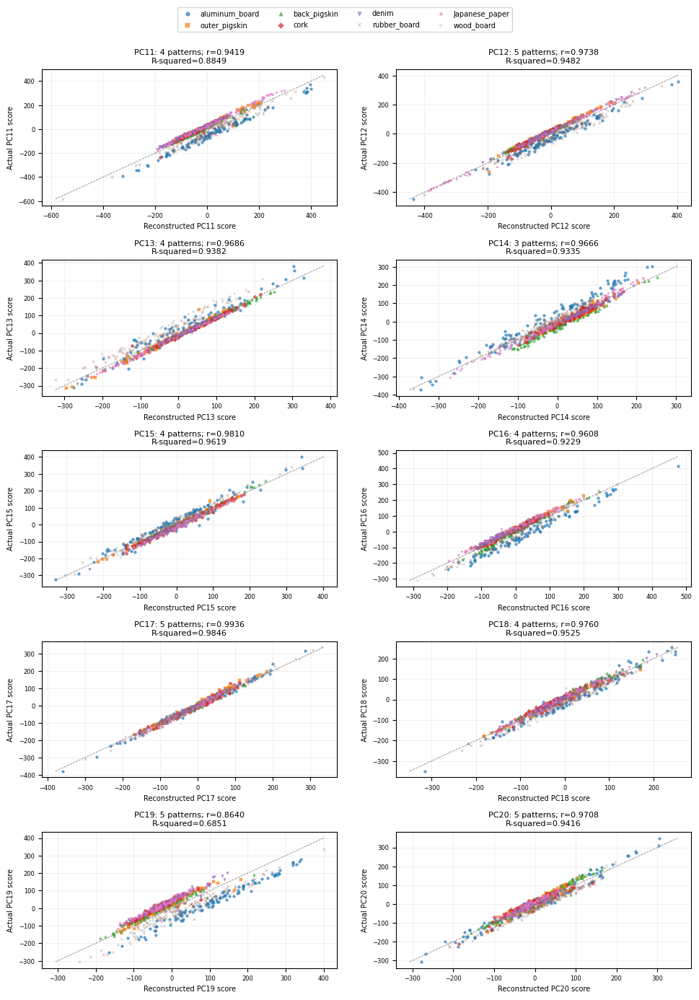

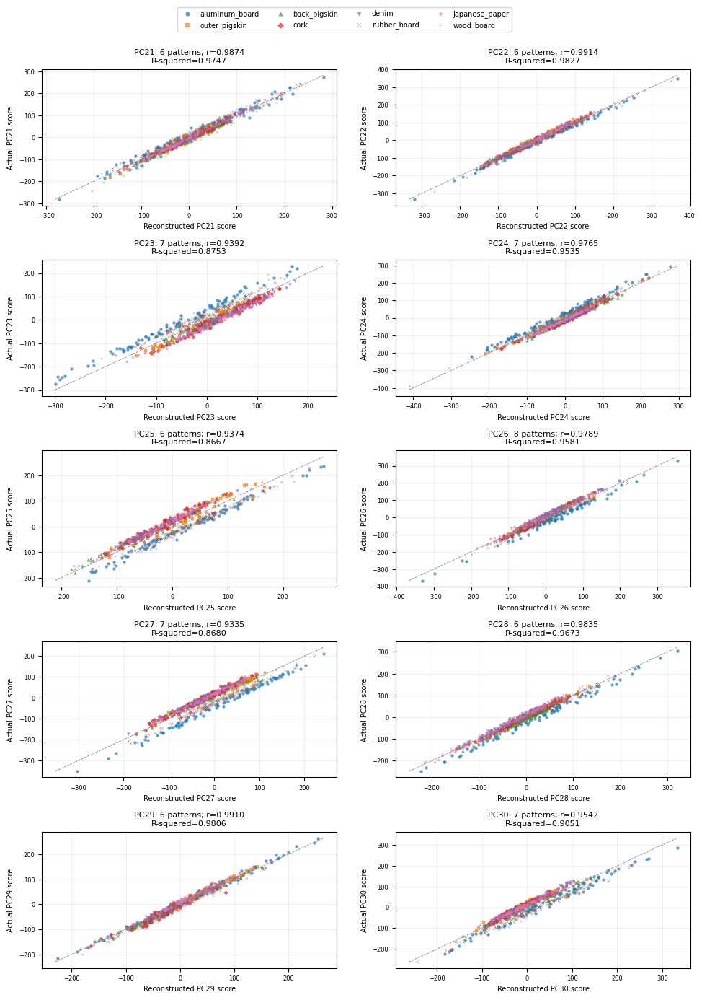

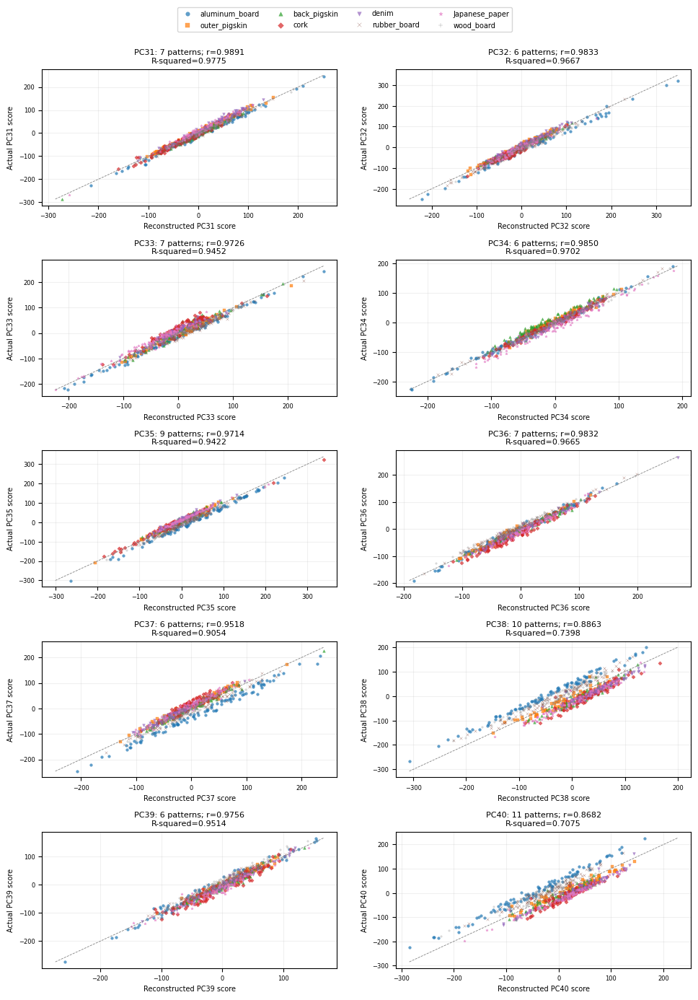

Pattern counts: mean R-squared across 5 splits. Scatter plots: held-out trials of split 1. No files saved.


In [5]:
# 学習側PCAの係数をSVDで分解し、少数パターンで評価側PCスコアを再現する。
# 既存の分類用分割の先頭5回を使用。PCA・平均・分解は毎回学習試行のみで計算。
# パターン数は5分割の平均R²から選ぶため、このR²は独立した最終性能評価ではない。
from d_tools.pca import fit_pca, transform_pca
from threadpoolctl import threadpool_limits

if 'states' not in globals() or 'splits' not in globals():
    raise RuntimeError('先頭のセルで状態を読み込んでから実行してください。')
PATTERN_SPLITS = 5
PATTERN_THRESHOLDS = (0.90, 0.95, 0.99)
SCATTER_R2_THRESHOLD = 0.90
pattern_rank_limit = min(states.shape[1:])
pattern_r2_by_fold = []
pattern_first_fold = None
with threadpool_limits(limits=THREADS):
    for fold, (train_ids, test_ids) in enumerate(splits[:PATTERN_SPLITS], 1):
        model = fit_pca(states[train_ids], n_components=MAX_PCS)
        peak_rows = np.argmax(np.abs(model.axes), axis=0)
        signs = np.sign(model.axes[peak_rows, np.arange(MAX_PCS)])
        signs[signs == 0] = 1
        # W：PC×ニューロン×時間。固有値の平方根は掛けない。
        weight_maps = (model.axes * signs).T.reshape(MAX_PCS, *states.shape[1:])
        u, singular_values, vt = np.linalg.svd(weight_maps, full_matrices=False)
        evaluation_centered = states[test_ids].reshape(len(test_ids), -1) - model.mean
        actual_scores = transform_pca(states[test_ids], model) * signs
        denominator = np.sum((actual_scores-actual_scores.mean(axis=0))**2, axis=0)
        reconstructed_scores = np.zeros_like(actual_scores)
        fold_r2 = []
        first_fold_reconstructions = []
        for ell in range(pattern_rank_limit):
            # 第ellパターン = s * ニューロン重みa * 時間重みbの外積。
            rank_one_weights = (singular_values[:, ell, None, None]
                                * u[:, :, ell, None] * vt[:, None, ell, :])
            reconstructed_scores += evaluation_centered @ rank_one_weights.reshape(MAX_PCS, -1).T
            error = np.sum((actual_scores-reconstructed_scores)**2, axis=0)
            r_squared = np.full(MAX_PCS, np.nan)
            np.divide(error, denominator, out=r_squared, where=denominator > 0)
            fold_r2.append(1-r_squared)
            if fold == 1:
                first_fold_reconstructions.append(reconstructed_scores.copy())
        pattern_r2_by_fold.append(np.stack(fold_r2))
        if fold == 1:
            pattern_first_fold = {
                'actual': actual_scores, 'reconstructed': np.stack(first_fold_reconstructions),
                'labels': labels[test_ids], 'r2': np.stack(fold_r2),
            }
        print(f'[Pattern reconstruction] split {fold}/{PATTERN_SPLITS}')
pattern_r2_by_fold = np.stack(pattern_r2_by_fold)  # 分割×パターン数×PC
pattern_mean_r2 = pattern_r2_by_fold.mean(axis=0)
# R²はパターンを増やしても単調とは限らない。
# 以降のすべてのqでも基準を満たす、最小のqを採用する。
pattern_remaining_minimum_r2 = np.minimum.accumulate(pattern_mean_r2[::-1], axis=0)[::-1]
pattern_required_counts = {}
for threshold in PATTERN_THRESHOLDS:
    selected = np.full(MAX_PCS, np.nan)
    for k in range(MAX_PCS):
        candidates = np.flatnonzero(pattern_remaining_minimum_r2[:, k] >= threshold)
        if len(candidates):
            selected[k] = candidates[0]+1
    pattern_required_counts[threshold] = selected

# 1．0.90・0.95・0.99の基準を満たすパターン数。
fig, ax = plt.subplots(figsize=(15, 5.6), layout='constrained')
for threshold, marker, color in zip(PATTERN_THRESHOLDS, ['o', 's', '^'],
                                     ['tab:blue', 'tab:orange', 'tab:green']):
    ax.plot(np.arange(1, MAX_PCS+1), pattern_required_counts[threshold],
            marker=marker, color=color, markersize=4, linewidth=1.5,
            label=f'Mean held-out R-squared >= {threshold:.2f}')
ax.set(title='Patterns needed to reconstruct held-out PC scores',
       xlabel='Principal component', ylabel='Required number of neuron-time patterns',
       xlim=(0, MAX_PCS+1), ylim=(0, pattern_rank_limit+1))
ax.set_xticks(np.arange(1, MAX_PCS+1, 2))
ax.grid(True, alpha=0.25)
ax.legend(loc='upper right')
plt.show()

# 2．平均R²>=0.90で選んだqを使い、1回目の評価試行を表示する。
# 5分割平均で選ぶため、表示した1分割だけではR²が0.90未満になる場合がある。
pattern_scatter_counts = pattern_required_counts[SCATTER_R2_THRESHOLD]
pattern_scatter_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red',
                          'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray']
pattern_scatter_markers = ['o', 's', '^', 'D', 'v', 'x', '*', '+']
pattern_scatter_figures = []
for first_pc in range(0, MAX_PCS, 10):
    fig, axes = plt.subplots(5, 2, figsize=(10, 14), squeeze=False)
    fig.subplots_adjust(left=0.08, right=0.98, bottom=0.04, top=0.93,
                        wspace=0.20, hspace=0.40)
    for offset, ax in enumerate(axes.flat):
        k = first_pc + offset
        if k >= MAX_PCS:
            ax.set_visible(False)
            continue
        if not np.isfinite(pattern_scatter_counts[k]):
            ax.set_title(f'PC{k+1}: threshold not reached', fontsize=8)
            continue
        q = int(pattern_scatter_counts[k])
        x = pattern_first_fold['reconstructed'][q-1, :, k]
        y = pattern_first_fold['actual'][:, k]
        r = np.corrcoef(x, y)[0, 1]
        for class_id, (material, color, marker) in enumerate(
                zip(MATERIALS, pattern_scatter_colors, pattern_scatter_markers)):
            mask = pattern_first_fold['labels'] == class_id
            ax.scatter(x[mask], y[mask], s=7, color=color, marker=marker,
                       alpha=0.7, linewidths=0.3, label=material)
        lower, upper = min(x.min(), y.min()), max(x.max(), y.max())
        ax.plot([lower, upper], [lower, upper], '--', color='0.5', linewidth=0.6)
        ax.set_title(f'PC{k+1}: {q} patterns; r={r:.4f}\n'
                     f'R-squared={pattern_first_fold["r2"][q-1, k]:.4f}', fontsize=8)
        ax.set_xlabel(f'Reconstructed PC{k+1} score', fontsize=7)
        ax.set_ylabel(f'Actual PC{k+1} score', fontsize=7)
        ax.tick_params(labelsize=6)
        ax.grid(True, alpha=0.18)
    handles, names = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, names, loc='upper center', ncol=4, fontsize=7,
               bbox_to_anchor=(0.5, 0.995), markerscale=1.5)
    pattern_scatter_figures.append(fig)
    plt.show()
print(f'Pattern counts: mean R-squared across {len(pattern_r2_by_fold)} splits. '
      'Scatter plots: held-out trials of split 1. No files saved.')


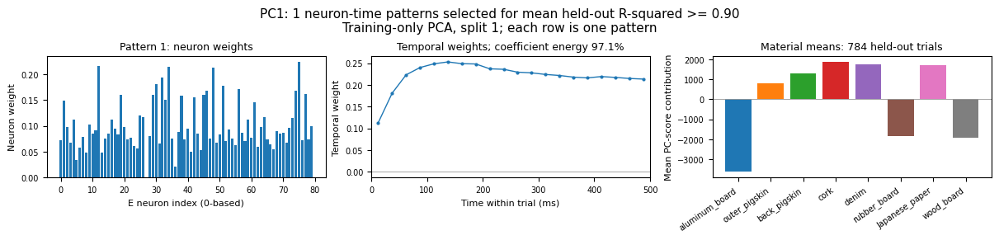

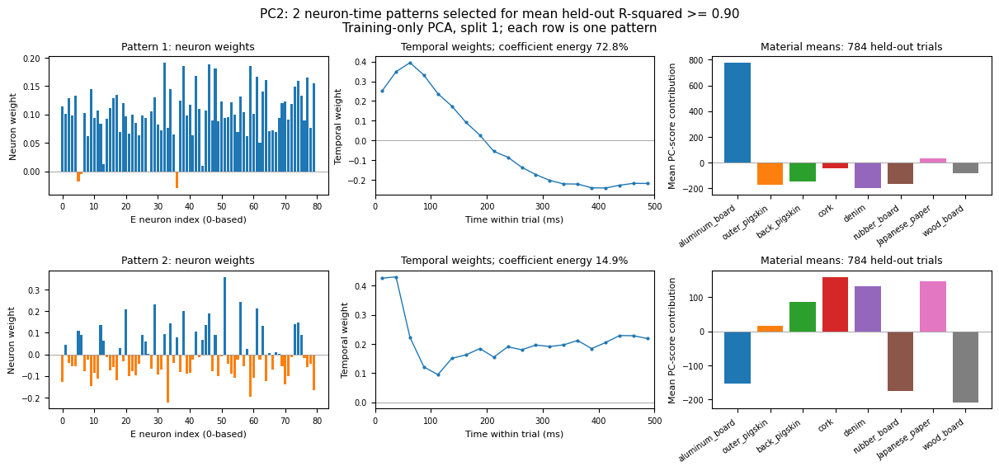

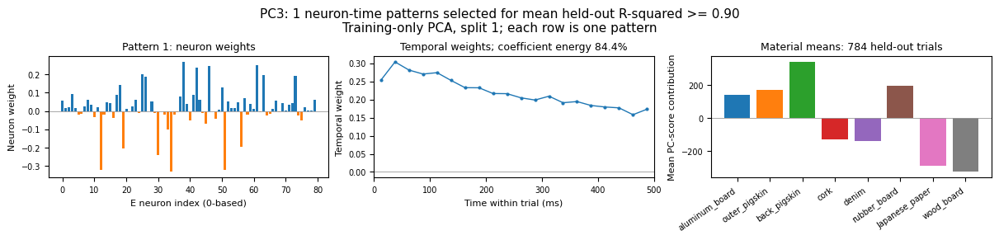

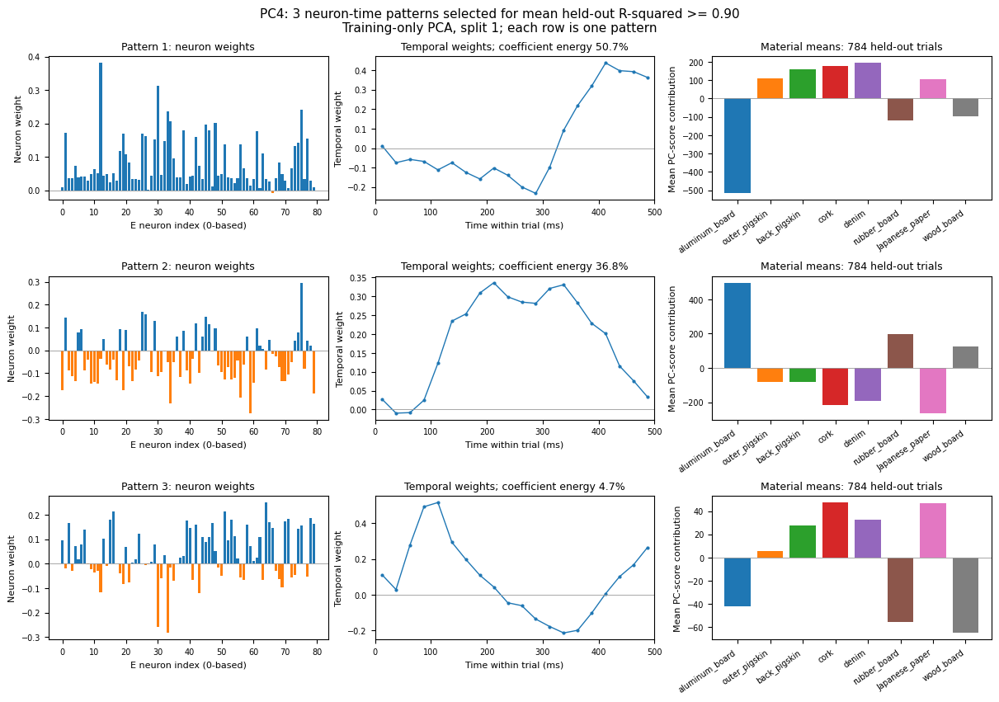

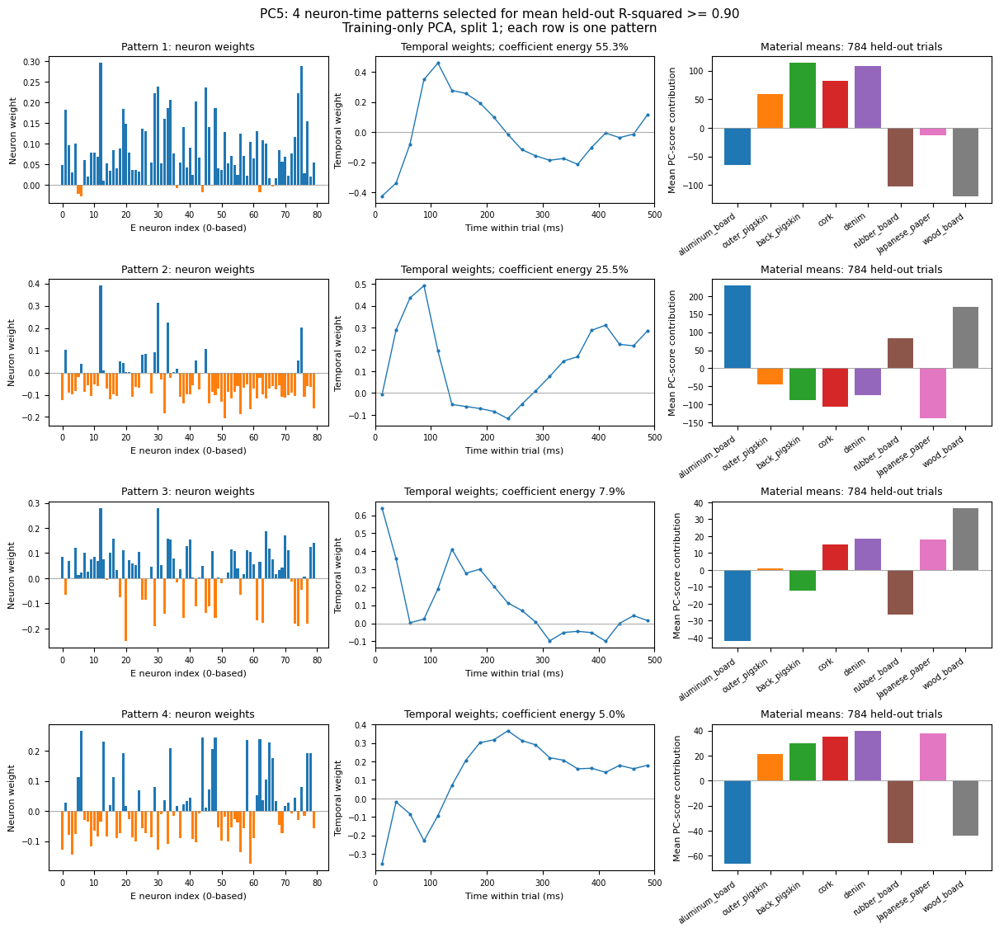

...

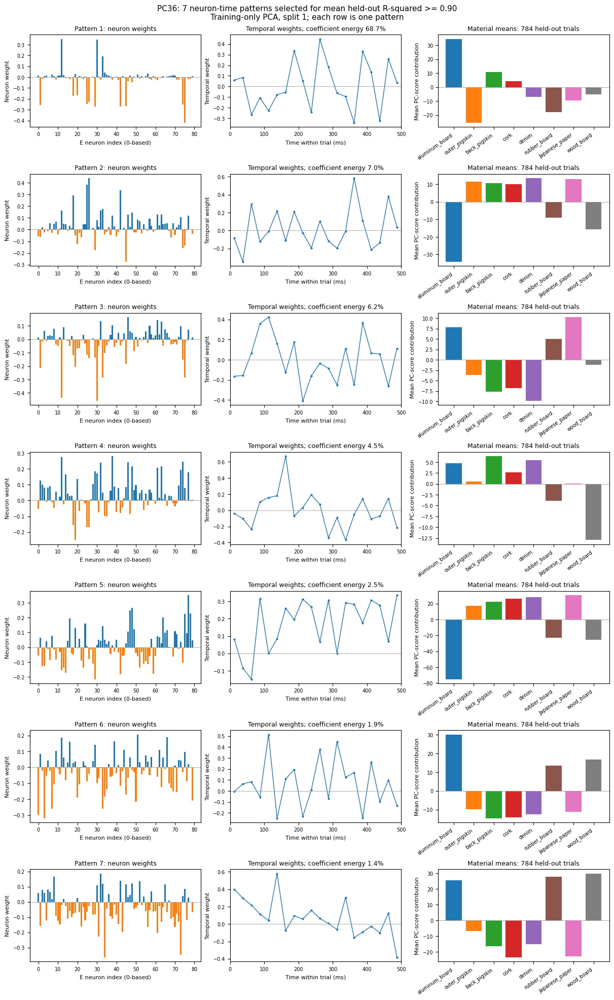

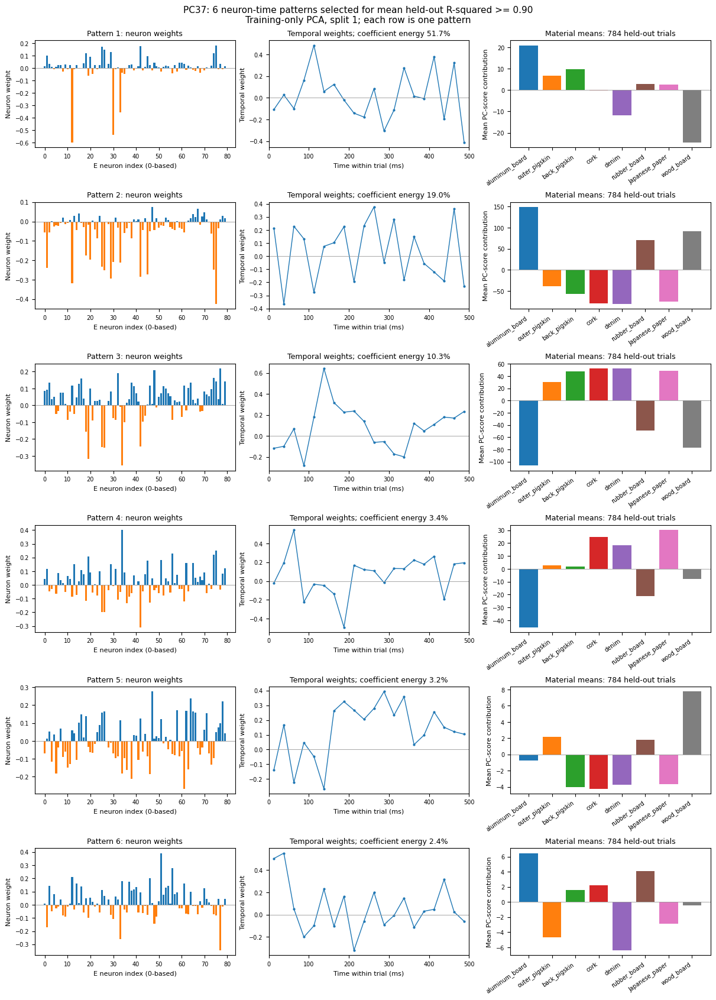

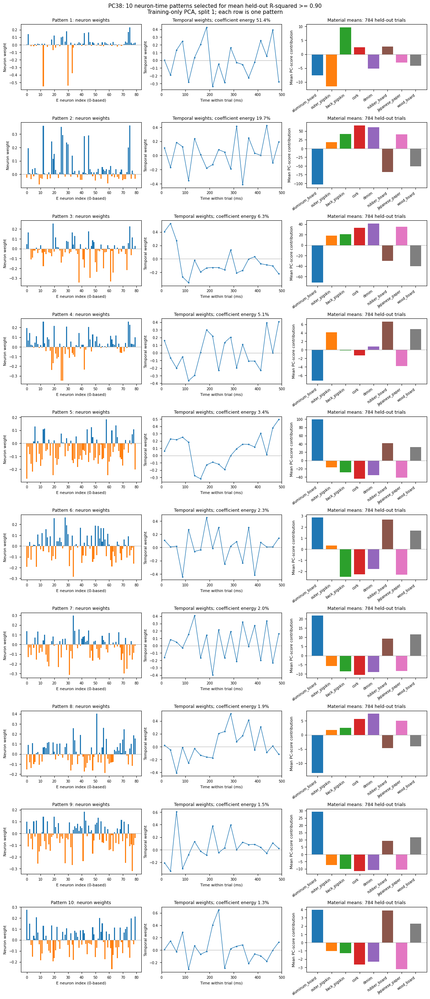

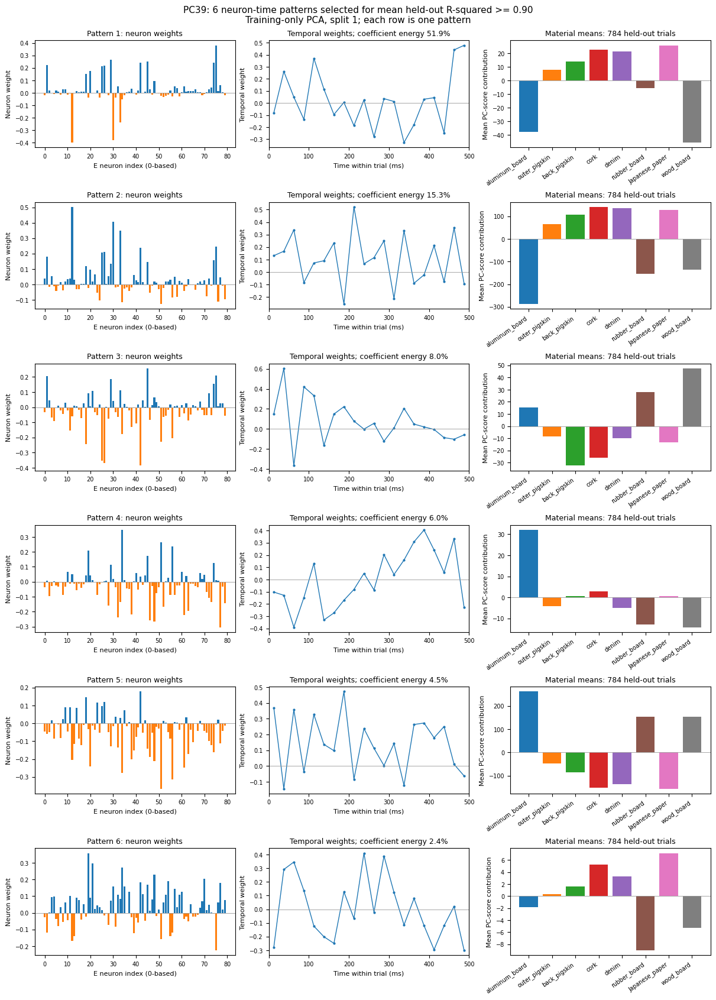

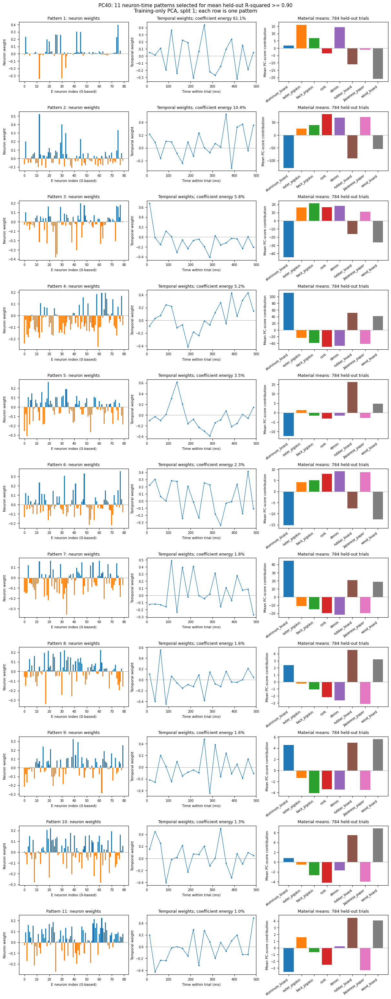

In [6]:
# 6. PC1-PC40: neuron weights / temporal weights / material contributions
# 各PCのパターン詳細。直前のパターン再現解析セルを実行してから使用する。
# 画像・CSVなどの結果ファイルは保存しない。
from d_tools.pca import fit_pca
from threadpoolctl import threadpool_limits

if 'pattern_first_fold' not in globals() or 'pattern_required_counts' not in globals():
    raise RuntimeError('先に5つ目のパターン再現解析セルを実行してください。')
# 旧版の解析セルにも対応するため、分割1の学習データから分解を取り出す。
with threadpool_limits(limits=THREADS):
    detail_model = fit_pca(states[splits[0][0]], n_components=MAX_PCS)
    detail_peak = np.argmax(np.abs(detail_model.axes), axis=0)
    detail_signs = np.sign(detail_model.axes[detail_peak, np.arange(MAX_PCS)])
    detail_signs[detail_signs == 0] = 1
    detail_weight_maps = (detail_model.axes*detail_signs).T.reshape(MAX_PCS, *states.shape[1:])
    detail_u, detail_s, detail_vt = np.linalg.svd(detail_weight_maps, full_matrices=False)

PATTERN_DETAIL_PCS = list(range(1, MAX_PCS+1))  # 特定のPCだけなら [1, 3, 40] など。
PATTERN_DETAIL_THRESHOLD = 0.90
pattern_detail_counts = pattern_required_counts[PATTERN_DETAIL_THRESHOLD]
pattern_component_contributions = np.diff(pattern_first_fold['reconstructed'], axis=0,
    prepend=np.zeros_like(pattern_first_fold['reconstructed'][:1]))
pattern_detail_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red',
                         'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray']
pattern_detail_time_ms = (np.arange(states.shape[2])+0.5)*BIN_MS

def show_pc_pattern_details(pc_number):
    if not 1 <= pc_number <= MAX_PCS:
        raise ValueError(f'PC number must be between 1 and {MAX_PCS}')
    k = pc_number-1
    if not np.isfinite(pattern_detail_counts[k]):
        print(f'PC{pc_number}: threshold not reached')
        return None
    q = int(pattern_detail_counts[k])
    fig, axes = plt.subplots(q, 3, figsize=(12, 2.8*q), squeeze=False, layout='constrained')
    total_energy = np.sum(detail_s[k]**2)
    for ell in range(q):
        a = detail_u[k, :, ell].copy()
        b = detail_vt[k, ell].copy()
        sign = 1 if b[np.argmax(np.abs(b))] >= 0 else -1
        a *= sign
        b *= sign
        energy_percent = detail_s[k, ell]**2/total_energy*100
        ax = axes[ell, 0]
        ax.bar(NEURON_IDS, a, width=0.8, color=np.where(a >= 0, 'tab:blue', 'tab:orange'))
        ax.axhline(0, color='0.6', linewidth=0.6)
        ax.set(title=f'Pattern {ell+1}: neuron weights',
               xlabel='E neuron index (0-based)', ylabel='Neuron weight')
        ax = axes[ell, 1]
        ax.plot(pattern_detail_time_ms, b, 'o-', color='tab:blue', linewidth=1, markersize=2)
        ax.axhline(0, color='0.6', linewidth=0.6)
        ax.set(title=f'Temporal weights; coefficient energy {energy_percent:.1f}%',
               xlabel='Time within trial (ms)', ylabel='Temporal weight',
               xlim=(0, states.shape[2]*BIN_MS))
        contribution = pattern_component_contributions[ell, :, k]
        material_means = [contribution[pattern_first_fold['labels'] == c].mean()
                          for c in range(len(MATERIALS))]
        ax = axes[ell, 2]
        ax.bar(np.arange(len(MATERIALS)), material_means, color=pattern_detail_colors)
        ax.axhline(0, color='0.6', linewidth=0.6)
        ax.set_xticks(np.arange(len(MATERIALS)), MATERIALS, rotation=35, ha='right')
        ax.set(title=f'Material means: {len(contribution)} held-out trials',
               ylabel='Mean PC-score contribution')
        for ax in axes[ell]:
            ax.title.set_fontsize(9)
            ax.xaxis.label.set_size(8)
            ax.yaxis.label.set_size(8)
            ax.tick_params(labelsize=7)
    fig.suptitle(f'PC{pc_number}: {q} neuron-time patterns selected for mean held-out R-squared >= '
                 f'{PATTERN_DETAIL_THRESHOLD:.2f}\n'
                 'Training-only PCA, split 1; each row is one pattern', fontsize=11)
    return fig

for pc_number in PATTERN_DETAIL_PCS:
    pattern_detail_fig = show_pc_pattern_details(pc_number)
    if pattern_detail_fig is not None:
        plt.show()
        plt.close(pattern_detail_fig)


In [7]:
# このノートブック専用：主成分数ごとの分類評価。共通toolには置かない。
import time
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from d_tools.pca import fit_pca, transform_pca
from d_tools.classification import classify
from d_tools.evaluation import evaluate_classification


def evaluate_component_counts(states, labels, splits, *, n_components=40,
                              regularization=1e-6, threads=4, verbose=True) -> pd.DataFrame:
    """同じ分割で全特徴とPC1〜PCkの分類正答率を計算する。

    statesは「試行×ニューロン×時間ビン」または「試行×特徴」。
    splitsは(train_indices, test_indices)のリストで、添字はstatesの試行番号。
    各分割で学習試行だけから無活動特徴の除外とPCAを行う。標準化なし。
    返り値のaccuracyは0〜1。PCAは1分割につき1回だけ求め、上位k列を使う。
    """
    data = np.asarray(states, dtype=np.float64)
    y = np.asarray(labels)
    if (data.ndim not in (2, 3) or any(size == 0 for size in data.shape)
            or y.ndim != 1 or len(y) != len(data) or not np.isfinite(data).all()):
        raise ValueError('Expected finite trial states and one label per trial')
    if not isinstance(n_components, (int, np.integer)) or isinstance(n_components, bool) or n_components < 1:
        raise ValueError('n_components must be a positive integer')
    splits = list(splits)
    if not splits:
        raise ValueError('At least one training/evaluation split is required')
    X = data.reshape(len(data), -1)
    rows = []
    with threadpool_limits(limits=threads):
        for fold, (training_indices, test_indices) in enumerate(splits, 1):
            indices = []
            for values in [training_indices, test_indices]:
                values = np.asarray(values)
                if (values.ndim != 1 or not len(values) or not np.issubdtype(values.dtype, np.integer)
                        or np.any(values < 0) or np.any(values >= len(X)) or len(np.unique(values)) != len(values)):
                    raise ValueError('Split indices must be nonempty, unique valid integers')
                indices.append(values)
            tridx, teidx = indices
            if np.intersect1d(tridx, teidx).size:
                raise ValueError('Training and evaluation trials must not overlap')
            if not np.isin(y[teidx], y[tridx]).all():
                raise ValueError('Each evaluation class must occur in training')
            start = time.perf_counter()
            train, test = X[tridx], X[teidx]
            active = np.any(train != 0, axis=0)
            train, test = train[:, active], test[:, active]
            model = fit_pca(train, n_components=n_components)
            train_pc, test_pc = transform_pca(train, model), transform_pca(test, model)
            common = {'fold': fold, 'n_train': len(tridx), 'n_test': len(teidx),
                      'n_active_features': int(active.sum())}
            predicted = classify(train, y[tridx], test, regularization=regularization)
            full = evaluate_classification(y[teidx], predicted)['accuracy']
            rows.append({**common, 'representation': 'full_features', 'n_pcs': 0, 'accuracy': full})
            for k in range(1, n_components+1):
                predicted = classify(train_pc[:, :k], y[tridx], test_pc[:, :k], regularization=regularization)
                score = evaluate_classification(y[teidx], predicted)['accuracy']
                rows.append({**common, 'representation': 'PCA', 'n_pcs': k, 'accuracy': score})
            if verbose:
                elapsed = time.perf_counter()-start
                print(f'Split {fold}/{len(splits)} | Full: {full:.2%} | PC1-PC{n_components}: '
                      f'{rows[-1]["accuracy"]:.2%} | {elapsed:.1f} s', flush=True)
    return pd.DataFrame(rows)

# 結果はメモリ上で保持し、ファイルやキャッシュには保存しない。
start = time.perf_counter()
results = evaluate_component_counts(states, labels, splits,
    n_components=MAX_PCS, regularization=REGULARIZATION, threads=THREADS)
assert len(results) == n_splits*(MAX_PCS+1)
assert results.groupby('fold').size().eq(MAX_PCS+1).all()
print(f'{n_splits} splits | full features + PCs 1-{MAX_PCS} | {time.perf_counter()-start:.1f} s')


Split 1/10 | Full: 98.98% | PC1-PC40: 98.60% | 0.7 s
Split 2/10 | Full: 98.98% | PC1-PC40: 97.83% | 0.6 s
Split 3/10 | Full: 97.58% | PC1-PC40: 96.43% | 0.7 s
Split 4/10 | Full: 99.74% | PC1-PC40: 99.11% | 0.7 s
Split 5/10 | Full: 99.87% | PC1-PC40: 99.36% | 0.7 s
Split 6/10 | Full: 99.87% | PC1-PC40: 99.36% | 0.7 s
Split 7/10 | Full: 99.74% | PC1-PC40: 99.11% | 0.7 s
Split 8/10 | Full: 97.83% | PC1-PC40: 97.07% | 0.7 s
Split 9/10 | Full: 99.62% | PC1-PC40: 99.11% | 0.7 s
Split 10/10 | Full: 99.23% | PC1-PC40: 99.11% | 0.7 s
10 splits | full features + PCs 1-40 | 6.6 s


In [8]:
pca_results = results[results.representation.eq('PCA')]
full_results = results[results.representation.eq('full_features')]
summary = pca_results.groupby('n_pcs').accuracy.agg(['mean', 'std']).reset_index()
summary['mean_accuracy_percent'] = summary['mean']*100
summary['std_accuracy_percent'] = summary['std']*100
baseline_accuracy = float(full_results.accuracy.mean())
baseline_std = float(full_results.accuracy.std(ddof=1))

previous_path = SOURCE_DIR / 'classification' / 'accuracy_by_split.csv'
if previous_path.exists():
    previous = pd.read_csv(previous_path)
    if 'condition' in previous:
        previous = previous[previous.condition.eq('retuned')]
    for representation, current in [('full_features', full_results),
                                    ('PC40', pca_results[pca_results.n_pcs.eq(MAX_PCS)])]:
        old = previous[previous.representation.eq(representation)].sort_values('fold')
        if len(old) == n_splits:
            np.testing.assert_allclose(current.sort_values('fold').accuracy.to_numpy(),
                                       old.accuracy.to_numpy(), rtol=0, atol=1e-12)
            print(f'{representation}: 保存済み10分割の正答率と一致')

print(f'全{n_features}特徴：{baseline_accuracy*100:.4f}% ± {baseline_std*100:.4f}%')
display(summary[['n_pcs', 'mean_accuracy_percent', 'std_accuracy_percent']].round(4))


全1600特徴：99.1454% ± 0.8333%


,n_pcs,mean_accuracy_percent,std_accuracy_percent
0,1,39.0051,0.8371
1,2,58.3163,0.7858
2,3,84.1454,0.9565
3,4,86.4668,0.8428
4,5,88.2781,0.9246
5,6,89.8724,0.9182
6,7,90.4592,0.8018
7,8,91.1480,1.0843
8,9,93.6862,1.1221
9,10,94.5663,1.3217


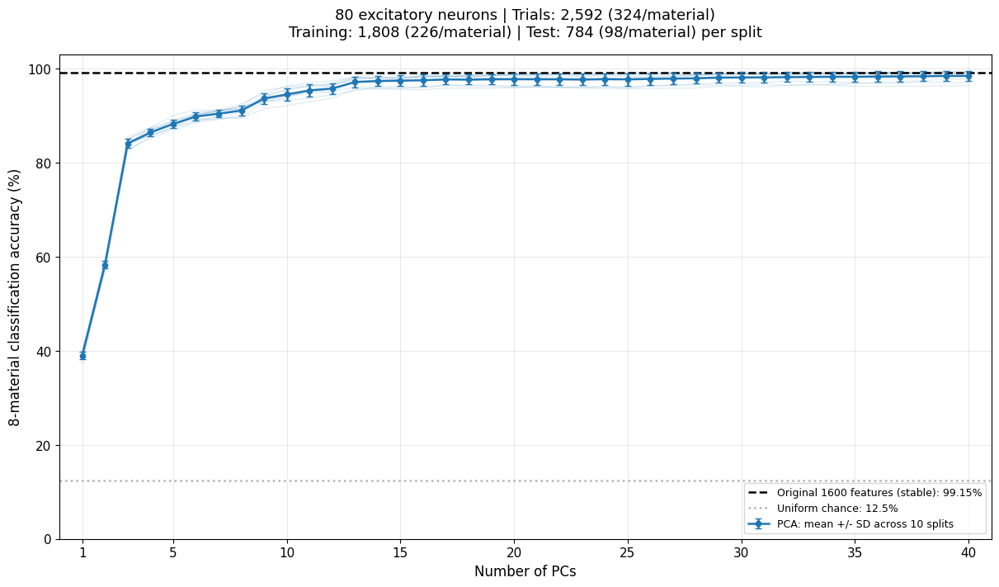

In [9]:
with plt.rc_context({'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 12}):
    fig, ax = plt.subplots(figsize=(12, 7), layout='constrained')
    for fold, group in pca_results.groupby('fold'):
        group = group.sort_values('n_pcs')
        ax.plot(group.n_pcs, group.accuracy*100, color='tab:blue', alpha=.13, lw=1)
    ax.axhline(baseline_accuracy*100, color='black', ls='--', lw=1.8,
               label=f'Original {n_features} features (stable): {baseline_accuracy*100:.2f}%')
    ax.axhline(100/n_classes, color='0.7', ls=':', lw=1.8,
               label=f'Uniform chance: {100/n_classes:g}%')
    ax.errorbar(summary.n_pcs, summary.mean_accuracy_percent,
                yerr=summary.std_accuracy_percent, fmt='o-', color='tab:blue',
                markersize=4.5, lw=1.8, capsize=3,
                label=f'PCA: mean +/- SD across {n_splits} splits')
    ax.set(xlabel='Number of PCs', ylabel=f'{n_classes}-material classification accuracy (%)',
           xlim=(0, MAX_PCS+1), ylim=(0, 103))
    ax.set_xticks([1, *range(5, MAX_PCS+1, 5)])
    ax.grid(True, alpha=.25)
    ax.set_title(f'{len(NEURON_IDS)} excitatory neurons | Trials: {len(states):,} '
                 f'({n_trials_per_material}/material)\n'
                 f'Training: {n_classes*n_train_each:,} ({n_train_each}/material) | '
                 f'Test: {n_classes*n_test_each:,} ({n_test_each}/material) per split', pad=16)
    ax.legend(loc='lower right', fontsize=9)
    plt.show()


80/80 liquid neurons | 10 selections | mean 99.15% | elapsed 3.8 s
75/80 liquid neurons | 10 selections | mean 99.16% | elapsed 39.7 s
70/80 liquid neurons | 10 selections | mean 99.18% | elapsed 74.0 s
65/80 liquid neurons | 10 selections | mean 99.17% | elapsed 106.6 s
60/80 liquid neurons | 10 selections | mean 99.15% | elapsed 137.5 s
55/80 liquid neurons | 10 selections | mean 99.12% | elapsed 166.8 s
50/80 liquid neurons | 10 selections | mean 99.03% | elapsed 194.4 s
45/80 liquid neurons | 10 selections | mean 99.01% | elapsed 220.2 s
40/80 liquid neurons | 10 selections | mean 98.97% | elapsed 244.1 s
35/80 liquid neurons | 10 selections | mean 98.73% | elapsed 266.2 s
30/80 liquid neurons | 10 selections | mean 98.55% | elapsed 285.9 s
25/80 liquid neurons | 10 selections | mean 98.27% | elapsed 303.4 s
20/80 liquid neurons | 10 selections | mean 97.24% | elapsed 316.2 s
15/80 liquid neurons | 10 selections | mean 92.33% | elapsed 326.3 s
10/80 liquid neurons | 10 selections |

,Liquid E neurons,Mean accuracy (%),SD (percentage points),Min accuracy (%),Max accuracy (%),Selections
0,80,99.145,0.000,99.145,99.145,10
1,75,99.158,0.083,99.069,99.286,10
2,70,99.179,0.087,99.031,99.311,10
3,65,99.175,0.100,99.031,99.349,10
4,60,99.151,0.160,98.776,99.337,10
5,55,99.120,0.198,98.827,99.388,10
6,50,99.031,0.269,98.469,99.337,10
7,45,99.011,0.276,98.520,99.337,10
8,40,98.972,0.250,98.418,99.260,10
9,35,98.732,0.217,98.367,99.043,10


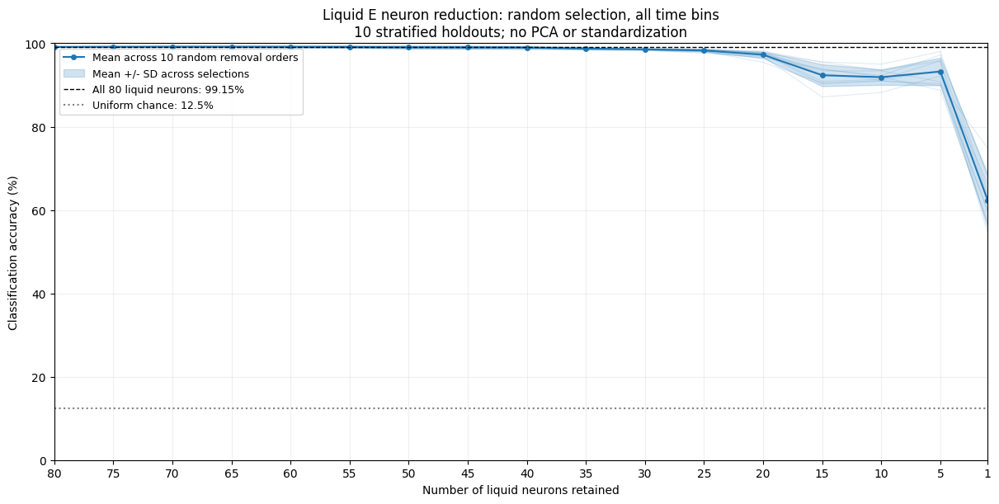

In [10]:
# --- Random liquid-neuron reduction: 10 removal orders, all time bins ---
# 80→75→70→…→5→1個へ減らす。ランダムな除去順を10通り作り、各個数で10回評価する。
# 同じ除去順では、少ない個数のニューロン集合は直前の集合の部分集合になる。
# 各集合で既存の層別ホールドアウト10回を使う。全時間ビンを使用し、PCA・標準化は行わない。
# 乱数はニューロン選択専用。学習・評価の試行分割は変えず、結果は外部保存しない。
from threadpoolctl import threadpool_limits

if 'states' not in globals() or 'splits' not in globals():
    raise RuntimeError('最初のコードセルで状態と試行分割を読み込んでください。')

NEURON_REDUCTION_REPEATS = 10
NEURON_REDUCTION_SEED = 12345
reduction_liquid_states = np.asarray(states)
reduction_n_neurons = reduction_liquid_states.shape[1]
reduction_rng = np.random.default_rng(NEURON_REDUCTION_SEED)
reduction_orders = np.stack([reduction_rng.permutation(reduction_n_neurons)
                             for _ in range(NEURON_REDUCTION_REPEATS)])
reduction_counts = np.unique(np.r_[np.arange(reduction_n_neurons, 0, -5), 1])[::-1]
# 既存のリキッド解析と同じホールドアウト10回を使用する。
# 分割間では評価試行が重なるため、全分割の延べ正解数/延べ評価数を集計する。
if reduction_liquid_states.ndim != 3 or len(reduction_liquid_states) != len(labels):
    raise ValueError('状態は（試行、ニューロン、時間ビン）で指定してください。')
if any(np.intersect1d(tr, te).size for tr, te in splits):
    raise ValueError('同じ分割内で学習試行と評価試行が重複しています。')


def evaluate_liquid_neuron_subset(neuron_ids):
    subset = reduction_liquid_states[:, neuron_ids, :]
    features = subset.reshape(len(subset), -1)
    correct, tested = 0, 0
    for train_ids, test_ids in splits:
        train_x = features[train_ids]
        # 無活動特徴の判定も学習側だけで行う。
        active = np.any(train_x != 0, axis=0)
        if active.any():
            predicted = classify(train_x[:, active], labels[train_ids],
                                 features[test_ids][:, active],
                                 regularization=REGULARIZATION)
        else:
            # 選んだニューロンが全て無活動なら、学習側の最多クラスを予測する。
            classes, counts = np.unique(labels[train_ids], return_counts=True)
            predicted = np.full(len(test_ids), classes[np.argmax(counts)])
        correct += int(np.count_nonzero(predicted == labels[test_ids]))
        tested += len(test_ids)
    return correct, tested


reduction_rows = []
reduction_cache = {}  # 全80個など、同じ集合の評価は1回だけ計算して再利用する。
reduction_start = time.perf_counter()
with threadpool_limits(limits=THREADS):
    for n_neurons in reduction_counts:
        count_accuracies = []
        for repeat, order in enumerate(reduction_orders, 1):
            neuron_ids = tuple(sorted(map(int, order[:n_neurons])))
            if neuron_ids not in reduction_cache:
                reduction_cache[neuron_ids] = evaluate_liquid_neuron_subset(neuron_ids)
            correct, tested = reduction_cache[neuron_ids]
            accuracy = correct / tested
            count_accuracies.append(accuracy)
            reduction_rows.append({'n_neurons': int(n_neurons), 'repeat': repeat,
                                   'neuron_ids': neuron_ids, 'correct': correct,
                                   'n_test': tested, 'accuracy': accuracy})
        print(f'{n_neurons:2d}/{reduction_n_neurons} liquid neurons | '
              f'{NEURON_REDUCTION_REPEATS} selections | '
              f'mean {np.mean(count_accuracies):.2%} | '
              f'elapsed {time.perf_counter()-reduction_start:.1f} s', flush=True)

liquid_neuron_reduction_results = pd.DataFrame(reduction_rows)
liquid_neuron_reduction_summary = (
    liquid_neuron_reduction_results.groupby('n_neurons', sort=False)
    .agg(mean_accuracy=('accuracy', 'mean'), sd_accuracy=('accuracy', 'std'),
         min_accuracy=('accuracy', 'min'), max_accuracy=('accuracy', 'max'),
         selections=('accuracy', 'size')).reset_index())
reduction_display = liquid_neuron_reduction_summary.rename(columns={
    'n_neurons': 'Liquid E neurons', 'mean_accuracy': 'Mean accuracy (%)',
    'sd_accuracy': 'SD (percentage points)', 'min_accuracy': 'Min accuracy (%)',
    'max_accuracy': 'Max accuracy (%)', 'selections': 'Selections'}).copy()
for column in ['Mean accuracy (%)', 'SD (percentage points)',
               'Min accuracy (%)', 'Max accuracy (%)']:
    reduction_display[column] *= 100
print('SD is across the 10 neuron selections, not across the holdout splits. '
      'All-neuron selections are identical.')
display(reduction_display.round(3))

fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
for repeat, part in liquid_neuron_reduction_results.groupby('repeat'):
    ax.plot(part['n_neurons'], part['accuracy'] * 100,
            color='tab:blue', alpha=0.14, linewidth=0.8)
x = liquid_neuron_reduction_summary['n_neurons'].to_numpy()
y = liquid_neuron_reduction_summary['mean_accuracy'].to_numpy() * 100
sd = liquid_neuron_reduction_summary['sd_accuracy'].to_numpy() * 100
ax.plot(x, y, 'o-', color='tab:blue', markersize=4,
        label=f'Mean across {NEURON_REDUCTION_REPEATS} random removal orders')
ax.fill_between(x, np.maximum(0, y-sd), np.minimum(100, y+sd),
                color='tab:blue', alpha=0.2, label='Mean +/- SD across selections')
ax.axhline(y[0], color='black', linestyle='--', linewidth=1,
           label=f'All {reduction_n_neurons} liquid neurons: {y[0]:.2f}%')
ax.axhline(100 / len(np.unique(labels)), color='gray', linestyle=':',
           label=f'Uniform chance: {100 / len(np.unique(labels)):g}%')
ax.set(xlabel='Number of liquid neurons retained', ylabel='Classification accuracy (%)',
       title=('Liquid E neuron reduction: random selection, all time bins\n'
              f'{len(splits)} stratified holdouts; no PCA or standardization'),
       ylim=(0, 100))
if reduction_n_neurons > 1:
    ax.set_xlim(reduction_n_neurons, 1)  # 左から右へ80→1個。
ax.set_xticks(sorted(set([1, reduction_n_neurons] +
                        list(range(5, reduction_n_neurons, 5)))))
ax.grid(alpha=0.2)
ax.legend(loc='best', fontsize=9)
plt.show()


# リキッド層の時間窓長ごとの素材分類評価（25 ms・50 ms刻み）

各試行の開始時点から、最初の25 ms、50 ms、…、500 msまでのリキッド状態を使って素材分類します。25 ms刻みの全20条件を評価し、50 ms刻み（50〜500 ms）はその中から抜き出して比較します。

各条件で80個の興奮性リキッドニューロンの時間ビンを特徴量として使用します。既存の層別10分割を固定して用い、学習側で無活動特徴だけを除外します。PCA・標準化は行わず、結果はノートブック上に表示し、ファイルには保存しません。


,window_ms,mean_accuracy_percent,sd_accuracy_percentage_points
0,25,72.538,2.052
1,50,86.645,1.919
2,75,88.367,1.533
3,100,66.747,1.875
4,125,82.538,1.780
5,150,94.413,1.090
6,175,96.722,1.225
7,200,97.564,1.106
8,225,98.380,1.092
9,250,98.571,0.978


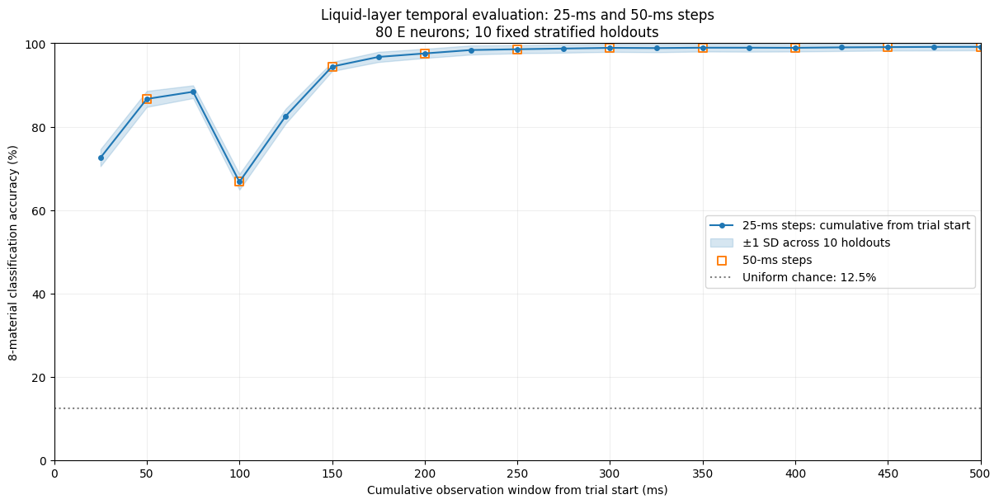

25-ms points: 25, 50, ..., 500 ms. 50-ms points are highlighted squares.
Accuracy is mean ± SD across the same 10 holdouts; output remains in notebook memory only.


In [11]:
# states: 試行 × Eニューロン × 25-ms時間ビン。各時間窓は試行開始からの累積区間。
from threadpoolctl import threadpool_limits

if 'states' not in globals() or 'labels' not in globals() or 'splits' not in globals():
    raise RuntimeError('最初のセルを先に実行してstates・labels・splitsを読み込んでください。')
if states.ndim != 3 or states.shape[-1] * BIN_MS != 500:
    raise ValueError(f'想定は試行×ニューロン×20個の25-msビンです。現在のshape={states.shape}, BIN_MS={BIN_MS}')

TIME_BIN_MS = float(BIN_MS)
window_bins = np.arange(1, states.shape[-1] + 1)
window_ms = window_bins * TIME_BIN_MS

time_window_rows = []
with threadpool_limits(limits=THREADS):
    for n_bins, duration_ms in zip(window_bins, window_ms):
        x = states[:, :, :n_bins].reshape(len(states), -1)
        for fold, (train_ids, test_ids) in enumerate(splits, 1):
            train_x = x[train_ids]
            active = np.any(train_x != 0, axis=0)
            if active.any():
                predicted = classify(train_x[:, active], labels[train_ids],
                                     x[test_ids][:, active],
                                     regularization=REGULARIZATION)
            else:
                class_ids, class_counts = np.unique(labels[train_ids], return_counts=True)
                predicted = np.full(len(test_ids), class_ids[np.argmax(class_counts)])
            metrics = evaluate_classification(labels[test_ids], predicted,
                                              labels=np.arange(n_classes))
            time_window_rows.append({
                'window_ms': int(round(duration_ms)),
                'n_time_bins': int(n_bins),
                'fold': int(fold),
                'accuracy': float(metrics['accuracy']),
                'n_active_features': int(active.sum()),
            })

time_window_results = pd.DataFrame(time_window_rows)
time_window_summary = (time_window_results.groupby(['window_ms', 'n_time_bins'])['accuracy']
                       .agg(mean_accuracy='mean', sd_accuracy='std').reset_index())
time_window_summary['mean_accuracy_percent'] = 100 * time_window_summary['mean_accuracy']
time_window_summary['sd_accuracy_percentage_points'] = 100 * time_window_summary['sd_accuracy']

display(time_window_summary[['window_ms', 'mean_accuracy_percent',
                             'sd_accuracy_percentage_points']].round(3))

fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
x_ms = time_window_summary['window_ms'].to_numpy()
y = time_window_summary['mean_accuracy_percent'].to_numpy()
sd = time_window_summary['sd_accuracy_percentage_points'].to_numpy()
ax.plot(x_ms, y, 'o-', color='tab:blue', markersize=4,
        label='25-ms steps: cumulative from trial start')
ax.fill_between(x_ms, np.maximum(0, y-sd), np.minimum(100, y+sd),
                color='tab:blue', alpha=.18, label='±1 SD across 10 holdouts')
mask_50ms = (x_ms % 50 == 0)
ax.scatter(x_ms[mask_50ms], y[mask_50ms], marker='s', s=42,
           facecolors='white', edgecolors='tab:orange', linewidths=1.4,
           label='50-ms steps')
ax.axhline(100 / n_classes, color='gray', linestyle=':',
           label=f'Uniform chance: {100/n_classes:.1f}%')
ax.set(xlabel='Cumulative observation window from trial start (ms)',
       ylabel='8-material classification accuracy (%)',
       title=('Liquid-layer temporal evaluation: 25-ms and 50-ms steps\n'
              f'{len(NEURON_IDS)} E neurons; {n_splits} fixed stratified holdouts'),
       xlim=(0, 500), ylim=(0, 100))
ax.set_xticks(np.arange(0, 501, 50))
ax.grid(alpha=.2)
ax.legend(loc='best')
plt.show()
print('25-ms points: 25, 50, ..., 500 ms. 50-ms points are highlighted squares.')
print('Accuracy is mean ± SD across the same 10 holdouts; output remains in notebook memory only.')
